## 🤖 Complete Plant Simulation Specification: Discrete-Time Open-Loop Asymmetric 4-Omni Robot Model

This cell specifies the comprehensive mathematical framework for the 4-wheel omni-directional mobile robot simulation. The architecture accounts for **asymmetric wheel layouts**, **dynamic multi-axis weight transfer (pitch and roll)**, **non-calibrated hardware parameters**, and **LuGre bristle floor friction boundaries** evaluated via **implicit exponential discrete-time updates** at a fixed sampling interval $\Delta T = 1\text{ ms}$ ($1\text{ kHz}$ loop rate).

---
<details>
<summary><b> Open this for the full specification of the simulation equations</b></summary>


### 1. Parameters & Variable Definitions

#### 🛠️ Hardware & Structural Parameters (Henry Calibrated Constants)
* $M_r$ : Total mass of the robot chassis
* $J_{zz}$: Rotational mass moment of inertia around vertical Z-axis
* $J_w $: Rotational moment of inertia of a wheel/rotor assembly
* $R_b$ : Geometric base radius from Center of Mass (CoM) to wheel contact points
* $r $: Operating radius of omni-wheel tires
* $\alpha_f$ = : Front wheel mounting angle relative to local $+x_r$ axis
* $\alpha_b $= : Rear wheel mounting angle relative to local $+x_r$ axis
* $h$: Height of Center of Mass (CoM) above ground plane
* $R$ , $L_m$ : DC motor armature winding resistance and inductance
* $K_t $= $K_b$ : Electromechanical torque and back-EMF constants
* $C_{rr}$ : Floor-tire rolling resistance coefficient
* $\mu_s$ , $\mu_k$ : Static and kinetic floor-tire friction coefficients
* $\delta$ : LuGre presliding bristle deflection limit ($2\,\mu\text{m}$)
* $\zeta $: LuGre bristle damping ratio fraction against rim inertia
* $v_\sigma$ : Slip velocity threshold where bristle damping fades out
* $v_c $: Creep regularization velocity preventing division by zero at rest
* $\alpha_d $: Stribeck exponential decay rate from static to kinetic friction
* $\varepsilon $: Hyperbolic tangent smoothing speed for rolling resistance drag

---

### 2. Signal Tracker Definitions

At each sample time step $k$, the discrete simulation cycle processes the following variables:

#### System Inputs
* $\mathbf{V}_k = [V_{1,k}, V_{2,k}, V_{3,k}, V_{4,k}]^\top$: Armature terminal voltage commands (Volts).

#### Tracked Memory Integration States
* $\mathbf{I}_k = [i_{1,k}, i_{2,k}, i_{3,k}, i_{4,k}]^\top$: Motor armature currents (Amperes).
* $\mathbf{\Omega}_k = [\omega_{1,k}, \omega_{2,k}, \omega_{3,k}, \omega_{4,k}]^\top$: Wheel angular velocities (rad/s).
* $\mathbf{z}_k = [z_{1,k}, z_{2,k}, z_{3,k}, z_{4,k}]^\top$: LuGre normalized bristle deflections (meters / normalized).
* $\mathbf{\dot{X}}_{r,k} = [\dot{x}_{r,k}, \dot{y}_{r,k}, \dot{\theta}_{k}]^\top$: Local chassis velocities (m/s Right, m/s Forward, rad/s Yaw).
* $\mathbf{\ddot{X}}_{r,k-1} = [a_{x,r,k-1}, a_{y,r,k-1}, \alpha_{r,k-1}]^\top$: Historical chassis accelerations from step $k-1$ (m/s², m/s², rad/s²).
* $\mathbf{\dot{X}}_{g,k} = [\dot{x}_{g,k}, \dot{y}_{g,k}, \dot{\theta}_{g,k}]^\top$: Global room frame velocities (m/s, m/s, rad/s).
* $\mathbf{X}_{g,k} = [x_k, y_k, \theta_k]^\top$: Global room frame navigation coordinates (meters, meters, radians).

---

### 3. Kinematic Mapping Matrix $\mathbf{H}$ (Body Frame: $+x_r$ Right, $+y_r$ Forward)

$$\mathbf{v}_{w,k} = \mathbf{H} \mathbf{\dot{X}}_{r,k}, \qquad \mathbf{H} = \begin{bmatrix} -\sin\alpha_f & \cos\alpha_f & R_b \\ -\sin\alpha_f & -\cos\alpha_f & R_b \\ \sin\alpha_b & -\cos\alpha_b & R_b \\ \sin\alpha_b & \cos\alpha_b & R_b \end{bmatrix}$$

---

### 4. Dynamic Normal Load Redistribution

With $+x_r$ Right (strafing) and $+y_r$ Forward (longitudinal):
$$y_f = R_b \sin\alpha_f = 0.03975\text{ m}, \qquad y_b = R_b \sin\alpha_b = 0.05622\text{ m}, \qquad L = y_f + y_b = 0.09597\text{ m}$$
$$x_f = R_b \cos\alpha_f = 0.06885\text{ m}, \qquad x_b = R_b \cos\alpha_b = 0.05622\text{ m}, \qquad \Sigma X^2 = x_f^2 + x_b^2 = 0.007901\text{ m}^2$$

#### Static Normal Force Distribution at Rest
$$F_{n,\text{front, static}} = \frac{M_r g y_b}{2 L} = 7.752\text{ N}, \qquad F_{n,\text{rear, static}} = \frac{M_r g y_f}{2 L} = 5.482\text{ N}$$

#### Dynamic Weight Shifts (Pitch due to $a_{y,\text{past}}$, Roll due to $a_{x,\text{past}}$)
$$\Delta F_{n,y} = \frac{M_r a_{y,\text{past}} h}{2 L}, \qquad \Delta F_{n,x,\text{front}} = \frac{x_f}{\Sigma X^2} \frac{M_r a_{x,\text{past}} h y_b}{L}, \qquad \Delta F_{n,x,\text{rear}} = \frac{x_b}{\Sigma X^2} \frac{M_r a_{x,\text{past}} h y_f}{L}$$

$$\mathbf{F}_{n,k} = \begin{bmatrix} F_{n,\text{front, static}} - \Delta F_{n,y} - \Delta F_{n,x,\text{front}} + w_{F,1} \\ F_{n,\text{front, static}} - \Delta F_{n,y} + \Delta F_{n,x,\text{front}} + w_{F,2} \\ F_{n,\text{rear, static}} + \Delta F_{n,y} + \Delta F_{n,x,\text{rear}} + w_{F,3} \\ F_{n,\text{rear, static}} + \Delta F_{n,y} - \Delta F_{n,x,\text{rear}} + w_{F,4} \end{bmatrix}$$

---

### 5. LuGre Bristle Friction & Discrete Integration

1. **Contact Slip Velocity along Rolling Axis:**
   $$v_{s,i,k} = (\mathbf{H} \mathbf{\dot{X}}_{r,k})_i - r \omega_{i,k}$$

2. **Smoothed Rolling Resistance Drag:**
   $$T_{\text{roll},i,k} = C_{rr} F_{n,i,k} r \tanh\left( \frac{\omega_{i,k}}{\varepsilon} \right)$$

3. **Stribeck Friction Curve & Local Characteristic Time Constant:**
   $$\mu_{d,i,k} = \mu_k + (\mu_s - \mu_k) e^{-\alpha_d |v_{s,i,k}|}$$
   $$z_{\text{ss},i,k} = \frac{v_{s,i,k} \mu_{d,i,k}}{\mu_s \sqrt{v_{s,i,k}^2 + v_c^2}}, \qquad \tau_{i,k} = \frac{\delta \mu_{d,i,k}}{\mu_s \sqrt{v_{s,i,k}^2 + v_c^2}}$$

4. **Implicit Exponential Discrete Bristle Update ($\Delta T = 1\text{ ms}$):**
   $$z_{i,k+1} = z_{i,k} e^{-\Delta T / \tau_{i,k}} + z_{\text{ss},i,k} \left( 1 - e^{-\Delta T / \tau_{i,k}} \right), \qquad \dot{z}_{i,k} = \frac{z_{i,k+1} - z_{i,k}}{\Delta T}$$

5. **Net Tractive Floor Force & Unified Wheel Speed Update:**
   $$\sigma_{1,i,k} = 2 \zeta \sqrt{ \frac{\mu_s F_{n,i,k}}{\delta} \frac{J_w}{r^2} } e^{-(v_{s,i,k} / v_\sigma)^2}$$
   $$F_{i,k} = -\left( \mu_s F_{n,i,k} z_{i,k+1} + \sigma_{1,i,k} \delta \dot{z}_{i,k} + \sigma_2 v_{s,i,k} \right)$$
   $$\omega_{i,k+1} = \omega_{i,k} + \frac{\Delta T}{J_w} \left( T_{m,i,k} - T_{\text{roll},i,k} - r F_{i,k} \right)$$

</details>


---
<details>
<summary><b> Open this for simulation flowchart </b></summary>


```text
==================================================
        SIMULATION STATE DATA (STEP K)
==================================================
 [Inputs] -> Voltages Vector V_1..4
 [Memory] -> Current i_k, Wheel Speeds omega_k
 [Memory] -> LuGre Bristle Deflections z_k
 [Memory] -> Local Chassis Speeds & Past Accel (a_x, a_y)
 [Memory] -> Global Coordinates [x, y, theta]
==================================================
                        |
                        v
  +--------------------------------------------+
  | Step 5.1: Motor Armature Current Update    |
  | di/dt = (V - R*i - Kb*omega) / Lm          |
  | i_{k+1} = i_k + dt * di/dt                 |
  | T_m = Kt * i_{k+1}                         |
  +--------------------------------------------+
                        |
                        v
  +--------------------------------------------+
  | Step 5.2: Dynamic Normal Force Distribution|
  | (x Right, y Forward Frame)                 |
  | Static load + Pitch (ay) + Roll (ax) + w_F |
  +--------------------------------------------+
                        |
                        v
  +--------------------------------------------+
  | Step 5.3: LuGre Bristle Friction Update    |
  | v_s = H*v_local - r*omega                  |
  | Exponential Discrete Update z_{k+1}        |
  | F_floor = - (mu_s*Fn*z + sigma_1*delta*z_dot) |
  +--------------------------------------------+
                        |
                        v
  +--------------------------------------------+
  | Step 5.4 & 5.5: Rigid Chassis Kinetics     |
  | a_local = M_inv * H^T * F_floor            |
  | v_local_{k+1} = v_local_k + dt * a_local   |
  | pos_global_{k+1} = pos_global + dt*R*v_local|
  +--------------------------------------------+
                        |
                        v
  +--------------------------------------------+
  | Step 5.6: Wheel Speed Integration          |
  | d_omega/dt = (T_m - T_roll - r*F_floor)/Jw |
  | omega_{k+1} = omega_k + dt * d_omega/dt    |
  +--------------------------------------------+
                        |
                        v
==================================================
        ADVANCE STATE TO STEP K+1
==================================================
```
</details>


### 📂 Omni Simulation Class Architecture

The `OmniRobotSimulation` class implements a modular, discrete-time physics engine executed at each time step $\Delta T$.

*   **`OmniMotorState`**: Data container that preserves and moves integrated memory states (armature currents, wheel speeds, LuGre bristle deflections, local/global velocities, and position coordinates) from step $k$ to $k+1$.
*   **`__init__`**: Sets hardware constants, calculates lever arms ($x_f, x_b, y_f, y_b$), builds the $4 \times 3$ kinematic transformation matrix $\mathbf{H}$, and builds the inverse rigid-body mass matrix $\mathbf{M}^{-1}$.
*   **`_build_kinematics_matrix`**: Constructs the $4 \times 3$ matrix projecting 3-DOF body velocity into individual wheel rolling velocities.
*   **`compute_electrical_subsystem`**: Integrates motor currents $\mathbf{I}_{k+1}$ via Forward Euler and calculates gross motor torques $\mathbf{T}_{m,k}$.
*   **`compute_dynamic_normal_forces`**: Evaluates vertical normal loads $\mathbf{F}_{n,k}$ with pitch/roll load shifts based on past accelerations ($a_{x,\text{past}}, a_{y,\text{past}}$) and vibration noise.
*   **`compute_contact_friction_interface`**: Evaluates LuGre bristle deflection states $\mathbf{z}_{k+1}$ using an **unconditionally stable exponential discrete update**, computing continuous traction forces and smoothed rolling drag.
*   **`advance_chassis_kinetics`**: Integrates Newton-Euler rigid chassis motion and maps body velocities into global coordinates.
*   **`step`**: Executes the master pipeline loop for one discrete time step $\Delta T$.


In [84]:
import numpy as np

class OmniMotorState:
    """
    Data container to log and preserve the electromechanical system states 
    at any discrete time step k.
    """
    def __init__(self):
        # Memory Integration States (Differential Cores)
        self.I = np.zeros(4)            # Armature currents [i1, i2, i3, i4] (A)
        self.omega = np.zeros(4)        # Wheel angular velocities [w1, w2, w3, w4] (rad/s)
        self.z = np.zeros(4)            # LuGre normalized bristle deflections [z1, z2, z3, z4]
        self.v_local = np.zeros(3)      # Local chassis velocities [vx (Right), vy (Forward), omega] (m/s, rad/s)
        self.a_local_past = np.zeros(3) # Historical chassis accelerations from step k-1 (m/s^2, rad/s^2)
        self.v_global = np.zeros(3)     # Global velocities [vx_g, vy_g, omega_g] (m/s, rad/s)
        self.pos_global = np.zeros(3)   # Global coordinates [x, y, theta] (m, rad)
        self.V_actual = np.zeros(4)     # Clipped applied terminal voltages [V1, V2, V3, V4] (V)
        
        # Tracked Logical Status Vector 
        self.S = np.zeros(4, dtype=bool) # Slip threshold indicators (False=Below slip band, True=Exceeds slip band)


class OmniRobotSimulation:
    """
    Physics engine plant managing an asymmetric 4-Omni wheel robot model
    with dynamic weight transfer and LuGre bristle floor friction boundaries.
    """
    def __init__(self, params: dict, random_seed: int = 42):
        """
        Initializes hardware constants, geometric parameters, and noise variances.
        """
        self.p = params
        self.dt = params['dt']
        
        # Pre-compute fixed kinematic tracking matrix (H)
        self.H = self._build_kinematics_matrix()

        # Dedicated random number generator state
        self.rng = np.random.default_rng(seed=random_seed)

        # --- BUILD THE MASS / INERTIA MATRIX (M) ---
        self.M = np.array([
            [self.p['Mr'], 0.0,           0.0],          # Mass acting on X acceleration (Right)
            [0.0,          self.p['Mr'],  0.0],          # Mass acting on Y acceleration (Forward)
            [0.0,          0.0,           self.p['Jzz']] # Rotational inertia acting on Alpha
        ])
        
        self.M_inv = np.linalg.inv(self.M)
        
        # Structural wheelbase lengths for weight distribution balances (+x Right, +y Forward)
        self.y_f = self.p['Rb'] * np.sin(self.p['alpha_f'])
        self.y_b = self.p['Rb'] * np.sin(self.p['alpha_b'])
        self.x_f = self.p['Rb'] * np.cos(self.p['alpha_f'])
        self.x_b = self.p['Rb'] * np.cos(self.p['alpha_b'])
        self.L = self.y_f + self.y_b
        self.sum_X2 = (self.x_f**2) + (self.x_b**2)
        self.m_rim = self.p['Jw'] / (self.p['r']**2)

    def _build_kinematics_matrix(self) -> np.ndarray:
        """Constructs the exact asymmetric velocity projection transformation matrix H."""
        af = self.p['alpha_f']
        ab = self.p['alpha_b']
        Rb = self.p['Rb']
        return np.array([
            [-np.sin(af),  np.cos(af), Rb],  # Wheel 1: Front Right
            [-np.sin(af), -np.cos(af), Rb],  # Wheel 2: Front Left
            [ np.sin(ab), -np.cos(ab), Rb],  # Wheel 3: Rear Left
            [ np.sin(ab),  np.cos(ab), Rb]   # Wheel 4: Rear Right
        ])

    def compute_electrical_subsystem(self, state: OmniMotorState, V_input: np.ndarray) -> np.ndarray:
        """
        Calculates Step 5.1: Enforces Voltage Hardpoint Saturation Bounds (V_max) 
        and Over-Current Protection Hardpoint Bounds (I_max). Advances motor armature 
        currents using Forward Euler discrete integration and maps them to gross 
        electromagnetic torques.
        """
        Lm = self.p['Lm']
        R = self.p['R']
        Kb = self.p['Kb']
        Kt = self.p['Kt']
        V_max = self.p.get('V_max', 12.0)
        I_max = self.p.get('I_max', 20.0)
        
        # 1. Voltage Hardpoint Clipping (Power Supply / H-Bridge Saturation Limit)
        V_clipped = np.clip(V_input, -V_max, V_max)
        state.V_actual = V_clipped
        
        # 2. Back-EMF & Current Derivative Calculation
        v_b = Kb * state.omega
        di_dt = (V_clipped - R * state.I - v_b) / Lm
        
        # 3. Discrete Current Integration with Over-Current Hardpoint Clipping
        I_unclipped = state.I + self.dt * di_dt
        state.I_next = np.clip(I_unclipped, -I_max, I_max)
        
        # 4. Gross Electromagnetic Motor Torque Output
        T_m = Kt * state.I_next
        return T_m

    def compute_dynamic_normal_forces(self, state: OmniMotorState) -> np.ndarray:
        """
        Calculates Step 5.2: Determines the vertical load profile for each wheel 
        by balancing static weight distributions with dynamic multi-axis pitch/roll 
        inertial moments (+x Right, +y Forward), plus random structural vibration noise.
        """
        Mr = self.p['Mr']
        g = 9.81
        h = self.p['h']
        L = self.L
        x_f = self.x_f
        x_b = self.x_b
        y_f = self.y_f
        y_b = self.y_b
        sum_X2 = self.sum_X2
        sigma_V = self.p['sigma_V']
        
        ax_past = state.a_local_past[0]  # Right
        ay_past = state.a_local_past[1]  # Forward
        
        # Base Static Distributions
        F_n_front_static = (Mr * g * y_b) / (2.0 * L)
        F_n_rear_static  = (Mr * g * y_f) / (2.0 * L)
        
        # Dynamic Weight Shifts
        delta_Fn_y = (Mr * ay_past * h) / (2.0 * L)  # Pitch due to forward accel
        lateral_moment_scale = (Mr * ax_past * h) / L
        delta_Fn_x_front = (x_f / sum_X2) * lateral_moment_scale * y_b  # Roll
        delta_Fn_x_rear  = (x_b / sum_X2) * lateral_moment_scale * y_f
        
        w_F = self.rng.normal(0.0, sigma_V, 4) if sigma_V > 0 else np.zeros(4)
        
        F_n = np.zeros(4)
        F_n[0] = F_n_front_static - delta_Fn_y - delta_Fn_x_front + w_F[0] # Wheel 1: Front Right
        F_n[1] = F_n_front_static - delta_Fn_y + delta_Fn_x_front + w_F[1] # Wheel 2: Front Left
        F_n[2] = F_n_rear_static  + delta_Fn_y + delta_Fn_x_rear  + w_F[2] # Wheel 3: Rear Left
        F_n[3] = F_n_rear_static  + delta_Fn_y - delta_Fn_x_rear  + w_F[3] # Wheel 4: Rear Right
        
        return np.maximum(0.0, F_n)

    def compute_contact_friction_interface(self, T_m: np.ndarray, F_n: np.ndarray, state: OmniMotorState) -> tuple:
        """
        Calculates Step 5.3: Evaluates LuGre bristle floor patch friction mechanics.
        Uses exact exponential discrete steps for stiff bristle deflection state.
        """
        r = self.p['r']
        Crr = self.p['Crr']
        mu_s_nom = self.p['mu_s']
        mu_k_nom = self.p['mu_k']
        sigma_mu = self.p['sigma_mu']
        delta_l = self.p['lugre_deflection']
        zeta = self.p['lugre_damping_ratio']
        v_sigma = self.p['lugre_damping_slip']
        v_c = self.p['lugre_creep']
        alpha_d = self.p['alpha_d']
        roll_smoothing = self.p['roll_smoothing']
        viscous = self.p['lugre_viscous']
        slip_band = self.p['slip_band']
        dt = self.dt
        
        w_mu = self.rng.normal(0.0, sigma_mu, 4) if sigma_mu > 0 else np.zeros(4)
        mu_s = np.maximum(0.0, mu_s_nom + w_mu)
        mu_k = np.maximum(0.0, mu_k_nom + w_mu)
        
        v_contact = self.H @ state.v_local
        v_s = v_contact - r * state.omega
        
        T_roll = Crr * F_n * r * np.tanh(state.omega / roll_smoothing)
        
        mu_d = mu_k + (mu_s - mu_k) * np.exp(-alpha_d * np.abs(v_s))
        denom = np.sqrt(v_s**2 + v_c**2)
        z_ss = (v_s * mu_d) / (mu_s * denom)
        tau = (delta_l * mu_d) / (mu_s * denom)
        
        exp_factor = np.exp(-dt / tau)
        z_next = state.z * exp_factor + z_ss * (1.0 - exp_factor)
        z_dot = (z_next - state.z) / dt
        
        sigma_1 = 2.0 * zeta * np.sqrt((mu_s * F_n / delta_l) * self.m_rim) * np.exp(-(v_s / v_sigma)**2)
        F_floor = -(mu_s * F_n * z_next + sigma_1 * delta_l * z_dot + viscous * v_s)
        
        T_load = -F_floor * r + T_roll
        S_status = np.abs(v_s) > slip_band
        
        return F_floor, T_load, S_status, z_next, T_roll

    def advance_chassis_kinetics(self, F_floor: np.ndarray, state: OmniMotorState) -> OmniMotorState:
        """
        Calculates Step 5.4 & 5.5: Advances rigid chassis velocities and global 
        position using Newton-Euler equations.
        """
        dt = self.dt
        theta_k = state.pos_global[2]
        
        a_local = self.M_inv @ (self.H.T @ F_floor)
        v_local_next = state.v_local + dt * a_local
        
        cos_t = np.cos(theta_k)
        sin_t = np.sin(theta_k)
        R_theta = np.array([
            [cos_t, -sin_t, 0.0],
            [sin_t,  cos_t, 0.0],
            [0.0,    0.0,   1.0]
        ])
        
        v_global_next = R_theta @ v_local_next
        pos_global_next = state.pos_global + dt * v_global_next
        
        next_state = OmniMotorState()
        next_state.v_local = v_local_next
        next_state.a_local_past = a_local
        next_state.v_global = v_global_next
        next_state.pos_global = pos_global_next
        
        return next_state

    def step(self, current_state: OmniMotorState, V_input: np.ndarray) -> tuple:
        """
        Executes the entire sequential discrete physics pipeline for a single time step dt.
        """
        r = self.p['r']
        Jw = self.p['Jw']
        dt = self.dt
        
        T_m = self.compute_electrical_subsystem(current_state, V_input)
        F_n = self.compute_dynamic_normal_forces(current_state)
        F_floor, T_load, S_status, z_next, T_roll = self.compute_contact_friction_interface(T_m, F_n, current_state)
        
        next_state = self.advance_chassis_kinetics(F_floor, current_state)
        next_state.I = current_state.I_next
        next_state.V_actual = current_state.V_actual
        next_state.S = S_status
        next_state.z = z_next
        
        d_omega_dt = (T_m - T_roll - r * F_floor) / Jw
        next_state.omega = current_state.omega + dt * d_omega_dt
        
        return next_state, T_load, S_status


```text
==========================================================================
                     SPATIAL REFERENCE FRAME LOGIC
==========================================================================

   GLOBAL FRAME (Fixed Room)               LOCAL FRAME (Robot Centric)
   
          ^+Y_global                              ^+Y_robot (Forward)
          |                                       |
          |                                       |
          +-------> +X_global                     +-------> +X_robot (Right/Strafing)
         /                                       /
        v +Z_global (Up)                        v +Z_robot (Up)

   • Orientation Theta (θ): Angle measured counter-clockwise from +X_global to +Y_robot.
   • Wheel 1: Front Right (Quadrant I)   at angle +alpha_f relative to +X_robot
   • Wheel 2: Front Left  (Quadrant II)  at angle +alpha_f relative to -X_robot
   • Wheel 3: Rear Left   (Quadrant III) at angle +alpha_b relative to -X_robot
   • Wheel 4: Rear Right  (Quadrant IV)  at angle +alpha_b relative to +X_robot
==========================================================================
```


### ⚙️ Plant Configuration & Initialization

This block configures the physical properties of the system using **estimated not-calibrated constants** and initializes the simulation workspace.

* **`simulation_parameters`**: Defines discrete time step , chassis mass and inertia , wheel geometry, motor constants , and floor friction parameters.


In [85]:
# 1. Define the simulation parameters dictionary (Henry calibrated constants)
simulation_parameters = {
    # Time Domain Constraints
    'dt': 0.001,               # Loop sampling interval (1 kHz loop rate)

    # System Power & Actuator Hardpoint Limits
    'V_max': 12.0,             # Terminal supply voltage saturation limit (Volts)
    'I_max': 20.0,             # Motor driver over-current protection limit (Amperes)

    # Robot Mechanical Properties
    'Mr': 2.698,               # Total mass of the robot chassis (kg)
    'Jzz': 0.007726,           # Chassis rotational inertia around Z-axis (kg*m^2)
    'Rb': 0.0795,              # Structural chassis base radius (meters)
    'h': 0.0611,               # Height of the Center of Mass above ground (meters)

    # Omni-Wheel Geometry
    'r': 0.0299,               # Operating radius of individual omni-wheels (meters)
    'Jw': 0.00018,          # Reflected rotor assembly inertia for Pololu 37D 30:1 (kg*m^2)           # Rotational inertia of a wheel+motor assembly (kg*m^2)
    'alpha_f': np.radians(30.0),# Front wheels mounting angle (converted to radians)
    'alpha_b': np.radians(45.0),# Rear wheels mounting angle (converted to radians)

    # DC Motor Electromechanical Properties
    'R': 2.18,                 # Armature winding resistance for Pololu 37D (Ohms)                 # Armature winding resistance (Ohms)
    'Lm': 0.0023,               # Armature winding inductance for Pololu 37D (Henries, 2.3 mH)            # Armature winding inductance (Henries)
    'Kt': 0.255,                # Torque constant for Pololu 37D 30:1 (Nm/A)              # Torque constant (Nm/A)
    'Kb': 0.255,                # Back-EMF constant for Pololu 37D 30:1 (V/(rad/s))              # Back-EMF constant (V/(rad/s))

    # Surface Contact and Friction Parameters
    'Crr': 0.025,              # Coefficient of rolling resistance
    'mu_s': 0.90,              # Nominal static coefficient of floor friction
    'mu_k': 0.422,             # Nominal kinetic coefficient of floor friction

    # LuGre Friction Model Parameters
    'lugre_deflection': 2e-6,  # Presliding bristle deflection limit (m)
    'lugre_damping_ratio': 1.0,# Damping ratio fraction
    'lugre_damping_slip': 0.005,# Damping fade-out slip speed (m/s)
    'lugre_creep': 0.0001,     # Regularization velocity (m/s)
    'alpha_d': 5.0,            # Stribeck decay scale (s/m)
    'roll_smoothing': 0.5,     # Rolling resistance tanh smoothing speed (rad/s)
    'lugre_viscous': 0.0,      # Floor viscous damping (N*s/m)
    'slip_band': 0.005,        # Slip flag threshold (m/s)

    # Environmental Disturbance Variations (Stochastic Noise)
    'sigma_V': 0.15,           # Structural vibration standard deviation (Newtons)
    'sigma_mu': 0.03           # Floor patch friction variance standard deviation
}

# 2. Instantiate the physics engine plant
robot_plant = OmniRobotSimulation(simulation_parameters, random_seed=42)

# 3. Instantiate a fresh initial state container
initial_state = OmniMotorState()

# 4. Generate the Comprehensive Plant Status Report
print("=======================================================================")
print("             🚀 OMNI-WHEEL PHYSICAL PLANT INITIALIZATION REPORT        ")
print("=======================================================================")
print(f" TIME INTERRUPT  | Sampling Rate: {1.0/robot_plant.dt:.0f} Hz | dt: {robot_plant.dt} s")
print("-----------------------------------------------------------------------")
print(" CHASSIS MECHANICAL PROPERTIES:")
print(f"  • Total Vehicle Mass (Mr):        {robot_plant.p['Mr']:.3f} kg")
print(f"  • Center of Mass Height (h):      {robot_plant.p['h']:.3f} m")
print(f"  • Rotational Inertia (Jzz):       {robot_plant.p['Jzz']:.5f} kg·m²")
print(f"  • Structural Base Radius (Rb):    {robot_plant.p['Rb']:.4f} m")
print(f"  • Front Mounting Angle (α_f):     {np.degrees(robot_plant.p['alpha_f']):.1f}° ")
print(f"  • Rear  Mounting Angle (α_b):     {np.degrees(robot_plant.p['alpha_b']):.1f}° ")
print("-----------------------------------------------------------------------")
print(" ELECTROMECHANICAL DRIVE & HARDPOINT BOUNDS:")
print(f"  • Supply Voltage Limit (V_max):   {robot_plant.p['V_max']:.1f} V      | Over-Current Limit (I_max): {robot_plant.p['I_max']:.1f} A")
print(f"  • Winding Resistance (R):         {robot_plant.p['R']:.3f} Ω      | Winding Inductance (Lm):    {robot_plant.p['Lm']:.6f} H")
print(f"  • Torque Scale Constant (Kt):     {robot_plant.p['Kt']:.4f} Nm/A  | Back-EMF Scale (Kb):        {robot_plant.p['Kb']:.4f} V/(rad/s)")
print(f"  • Assembly Rotor Inertia (Jw):    {robot_plant.p['Jw']:.7f} kg·m² | Operating Tire Radius (r):  {robot_plant.p['r']:.4f} m")
print("-----------------------------------------------------------------------")
print(" ENVIRONMENTAL BOUNDARY CONSTRAINTS & STOCHASTIC DISTURBANCES:")
print(f"  • Base Rolling Friction Drag (Crr):   {robot_plant.p['Crr']:.4f}  | Vibrational Force Noise (σ_V): {robot_plant.p['sigma_V']:.3f} N")
print(f"  • Nominal Sliding Friction (μ_k):     {robot_plant.p['mu_k']:.3f} | Nominal Static Friction (μ_s): {robot_plant.p['mu_s']:.3f}")
print(f"  • Patch Friction Variance (σ_μ):      {robot_plant.p['sigma_mu']:.3f}")
print("=======================================================================")


             🚀 OMNI-WHEEL PHYSICAL PLANT INITIALIZATION REPORT        
 TIME INTERRUPT  | Sampling Rate: 1000 Hz | dt: 0.001 s
-----------------------------------------------------------------------
 CHASSIS MECHANICAL PROPERTIES:
  • Total Vehicle Mass (Mr):        2.698 kg
  • Center of Mass Height (h):      0.061 m
  • Rotational Inertia (Jzz):       0.00773 kg·m²
  • Structural Base Radius (Rb):    0.0795 m
  • Front Mounting Angle (α_f):     30.0° 
  • Rear  Mounting Angle (α_b):     45.0° 
-----------------------------------------------------------------------
 ELECTROMECHANICAL DRIVE & HARDPOINT BOUNDS:
  • Supply Voltage Limit (V_max):   12.0 V      | Over-Current Limit (I_max): 20.0 A
  • Winding Resistance (R):         2.180 Ω      | Winding Inductance (Lm):    0.002300 H
  • Torque Scale Constant (Kt):     0.2550 Nm/A  | Back-EMF Scale (Kb):        0.2550 V/(rad/s)
  • Assembly Rotor Inertia (Jw):    0.0001800 kg·m² | Operating Tire Radius (r):  0.0299 m
--------------------

# 🧪 Kinematic & Dynamic Verification Testing

This section executes open-loop verification trials to validate the electromechanical motor re-coupling, asymmetric kinematics mapping ($\mathbf{H}$), and stick-slip friction boundaries under hardware-verified sign directions. 

### 📐 Structural Testing Grid Architecture
The execution pipeline performs a **multi-block comparative analysis** across two distinct physical frame designs and environmental settings:
1. **Block 1: Symmetric Frame Verification:** Configures the plant layout to an identical 45° alignment across all wheel lines ($\alpha_f = 45^\circ$, $\alpha_b = 45^\circ$).
2. **Block 2: Asymmetric Frame Verification:** Reverts the plant setup back to your custom asymmetric layout ($\alpha_f = 30^\circ$, $\alpha_b = 45^\circ$).
3. **Block 3: Asymmetric Frame With Boosted Voltage Verification:** Keeps the asymmetric frame but boosts the voltage to operate the voltage is a more ideal range but also cause slipping. The previous two verifications focus on the voltage direction and general kinematic so voltage is very low.   

### 🕹️ Verification Test Input Sequences
To isolate each independent degree of freedom, the simulation applies precise step voltage patterns across the four wheel motors:
*   **Test 1: Forward Motion ($\mathbf{V} = [V, -V, -V, V]^\top$):** Applies positive voltages to the right-side motors ($1, 4$) and negative voltages to the left-side motors ($2, 3$). This drives all wheels to push the ground backward symmetrically, canceling out lateral side forces and accelerating the robot straight ahead along its local $+X_r$ axis.
*   **Test 2: Lateral Side-Strafing ($\mathbf{V} = [-V, -V, V, V]^\top$):** Applies negative voltages to the front axle motors ($1, 2$) and positive voltages to the rear axle motors ($3, 4$). This mirrors the longitudinal forces across the front-to-back split line, causing forward and backward vectors to cancel out. The remaining lateral components combine to push the chassis cleanly sideways along its local $+Y_r$ axis.
*   **Test 3: Pure Rotational Spinning ($\mathbf{V} = [V, V, V, V]^\top$):** Applies uniform positive voltages to all four wheels simultaneously. Because every omni-wheel is mounted tangentially to the chassis base circle, spinning them all in the same rotational direction eliminates all linear translation vectors and creates a pure angular torque, spinning the robot counter-clockwise ($+\theta$) around its Center of Mass.

### 🔄 Dual-Pass State Conditions
To clearly isolate the degradation caused by environmental disturbances, each vehicle geometry executes a sequential dual-pass simulation:
*   **Ideal Pass (Reference Baseline):** Strips all noise configurations ($\sigma_V = 0.0$, $\sigma_\mu = 0.0$). The results render as soft, transparent curves representing perfect theoretical trajectories.
*   **Perturbed Pass (Real-World Overlay):** Activates a repeatable, seeded random number generator stream (`np.random.default_rng`) to overlay high-frequency structural chassis vibrations ($w_F$) and spatial friction coefficient patches ($w_\mu$).

### 📊 Logged Telemetry Variables
Each configuration runs the three directional maneuvers back-to-back over a 1.5-second time window (1500 discrete calculation steps) and generates a standalone 2x2 grid capturing:
*   **Applied Motor Terminal Voltages ($V_{1\dots4}$):** Verifies step-input directional polarities.
*   **Wheel Angular Velocities ($\omega_{1\dots4}$):** Monitors electromechanical back-EMF variations and independent rotor spinout integrations ($J_w$).
*   **Chassis Local Frame Speeds ($\dot{x}_r, \dot{y}_r, \dot{\theta}$):** Evaluates translational and angular momentum unbalances inside the mass matrix universe ($\mathbf{M}^{-1}\mathbf{H}^\top\mathbf{F}_k$).
*   **Global Position Tracking ($X-Y$ Trajectory Plane):** Visualizes dead-reckoning coordinate transformation drift paths directly overlaying ideal performance vs. noisy tracking realities.




Executing Block 1: Symmetric 45-45 Wheel Angle Configurations...


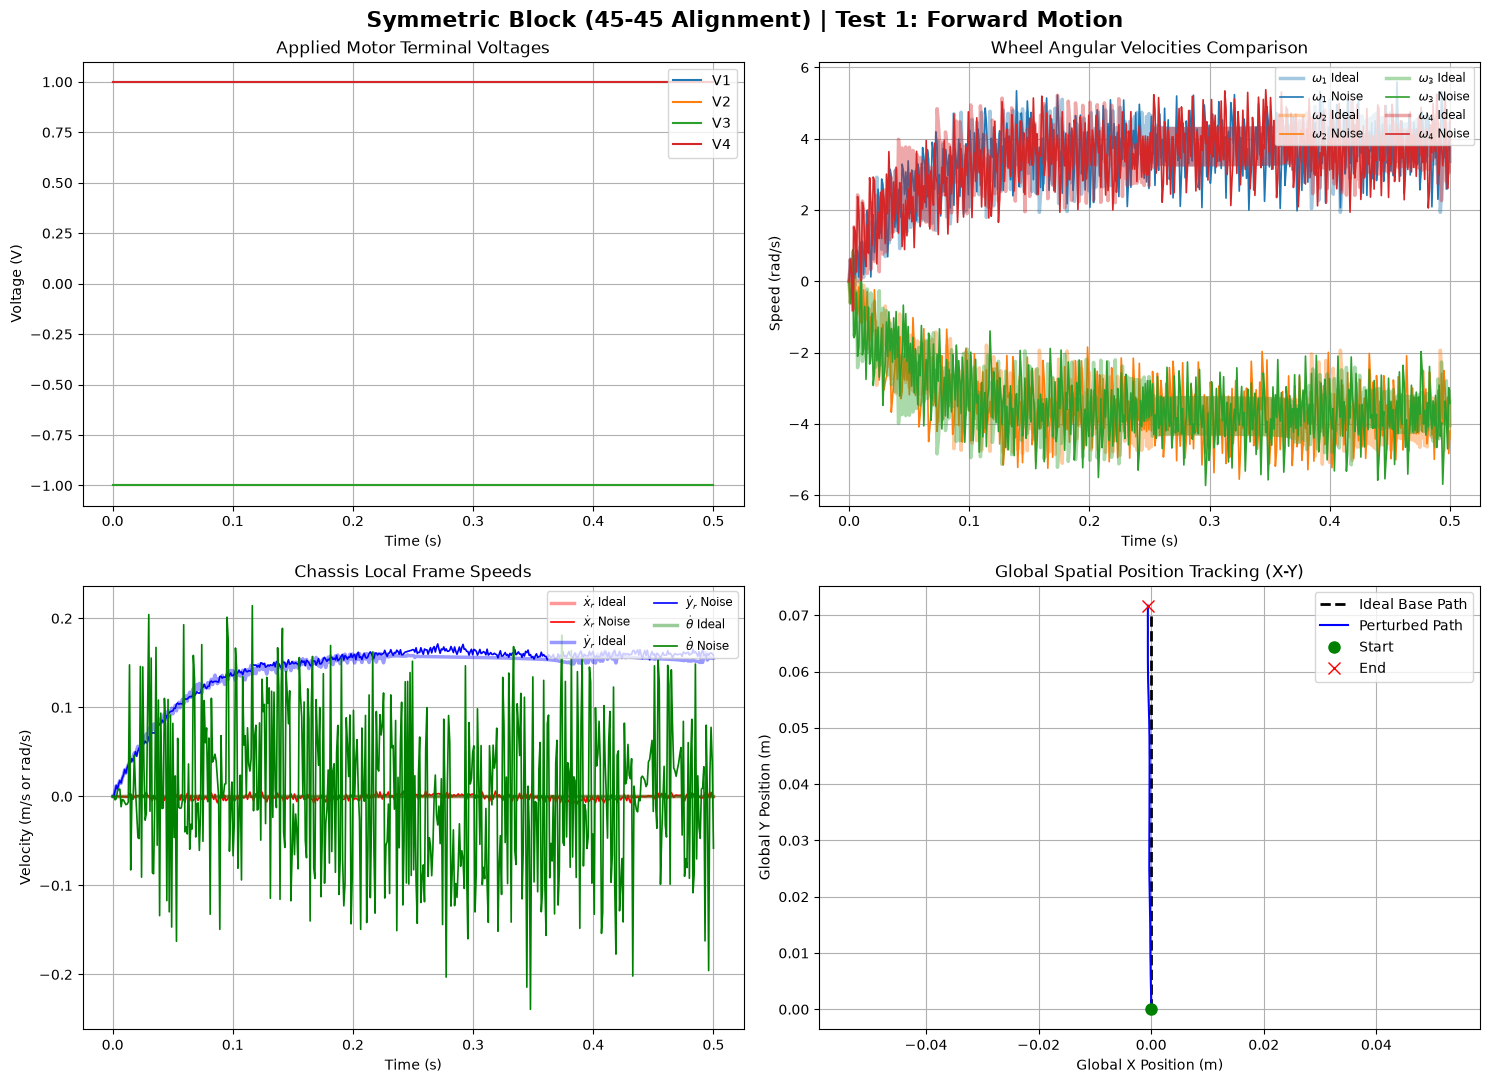

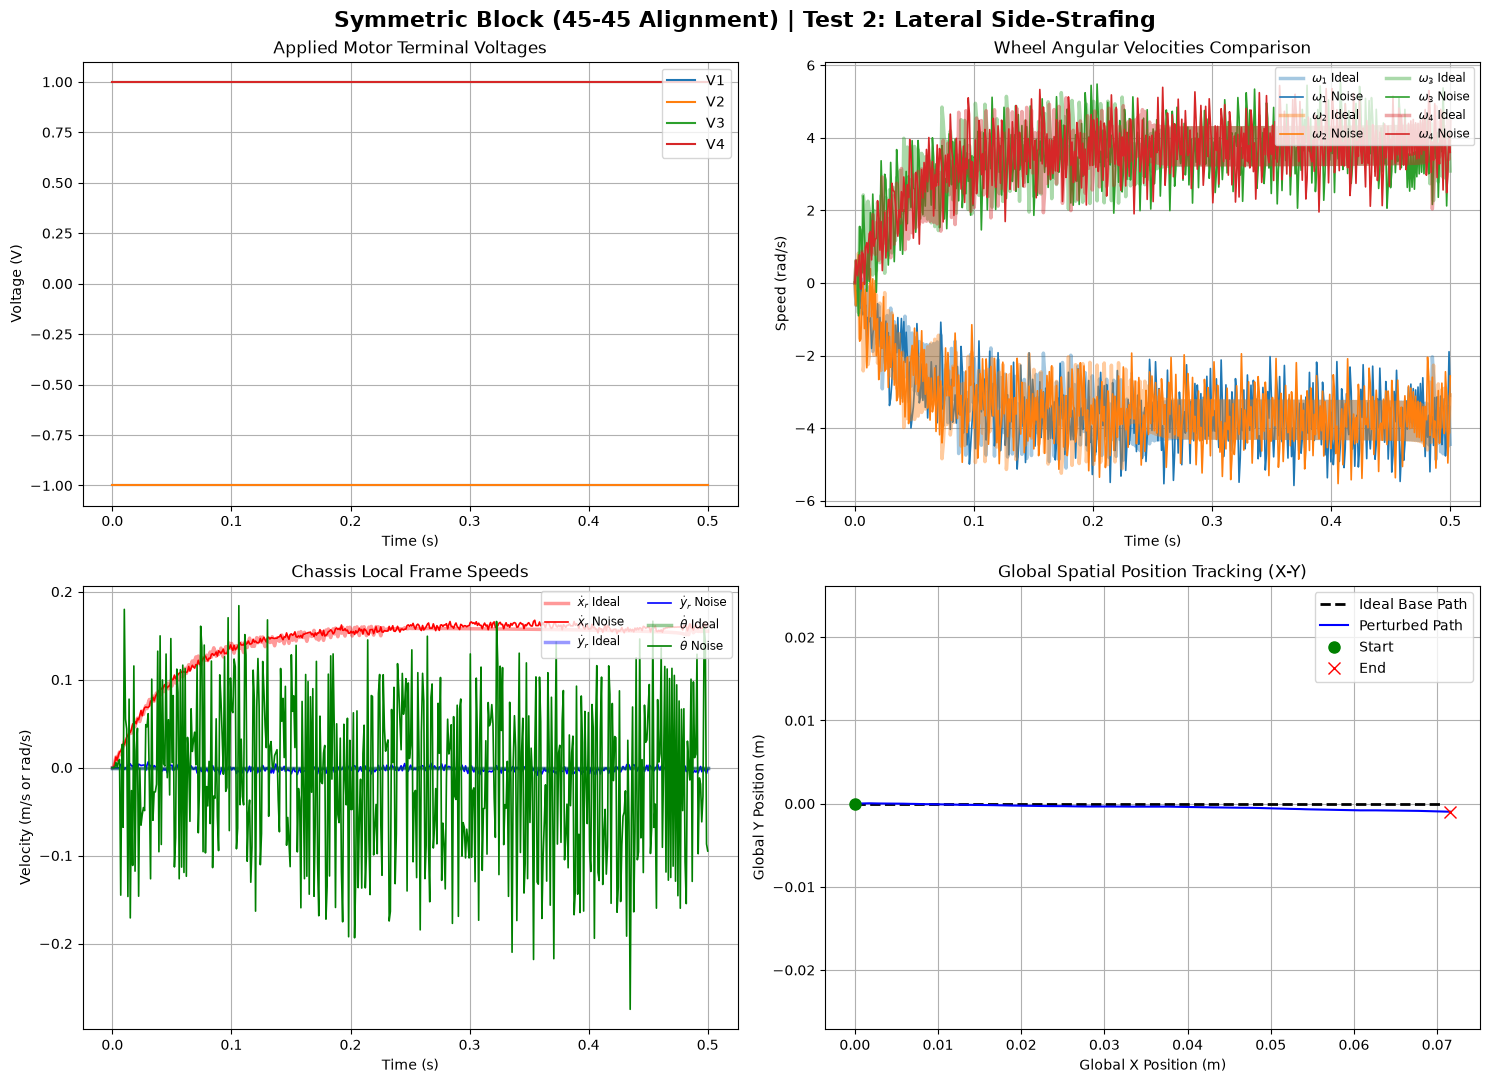

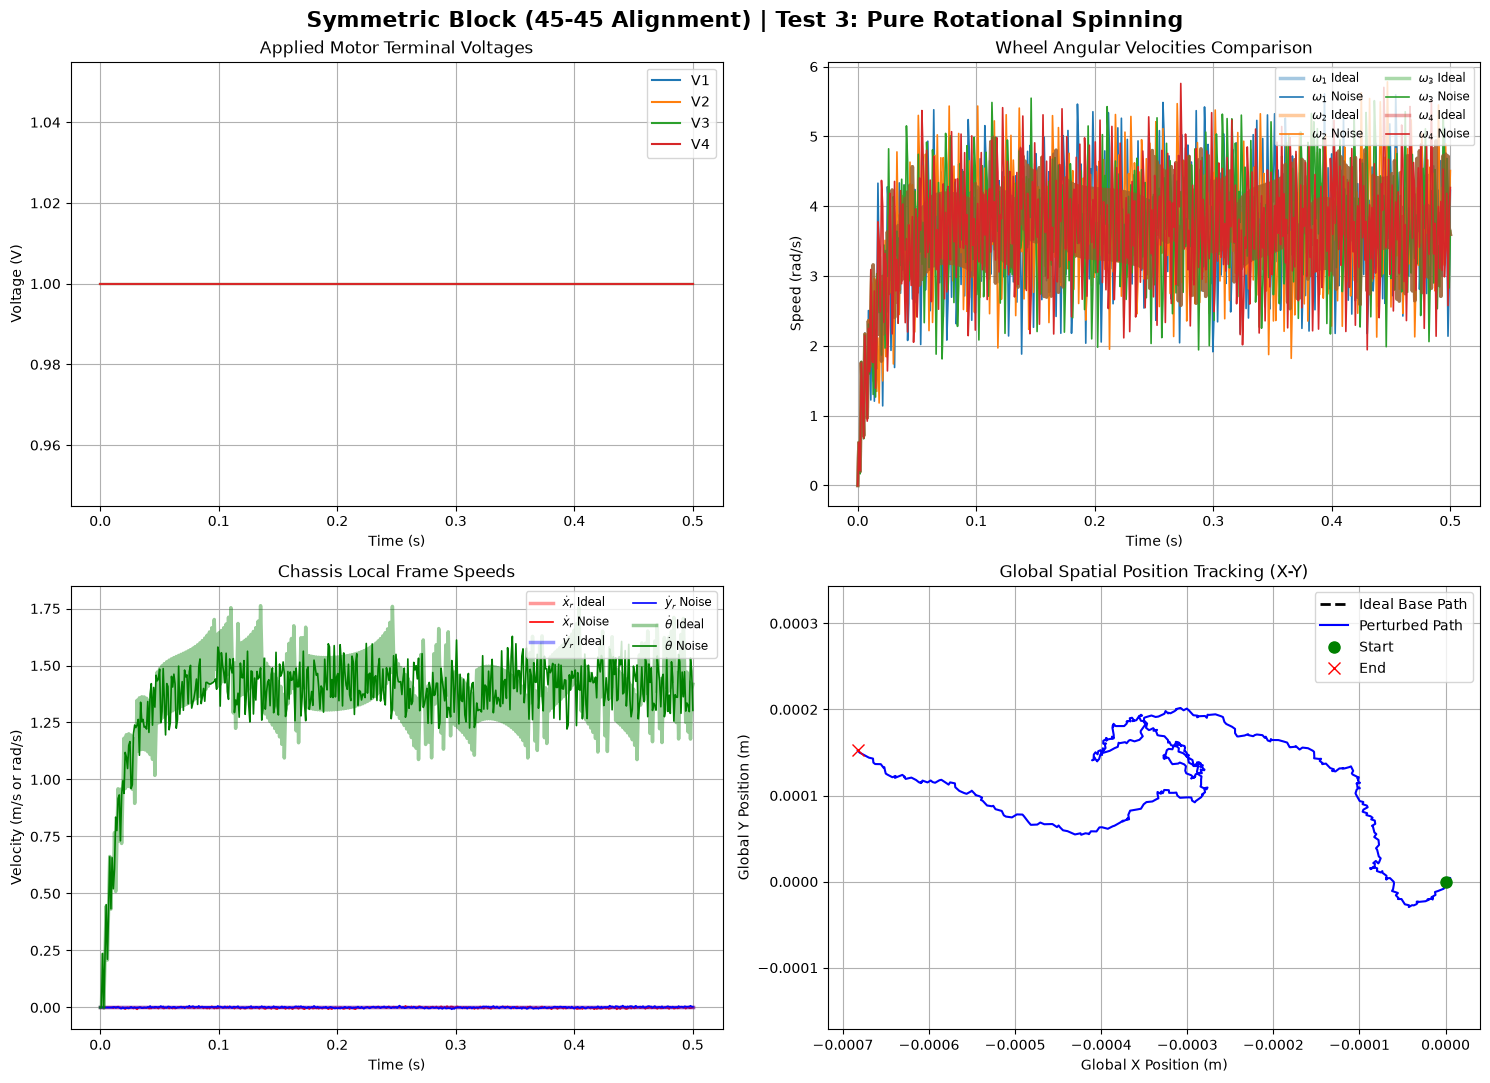

In [86]:
import numpy as np
import matplotlib.pyplot as plt

nominal_sigma_V = simulation_parameters['sigma_V']
nominal_sigma_mu = simulation_parameters['sigma_mu']

t_end = 0.5  
dt = simulation_parameters['dt']
steps = int(t_end / dt)
t_vec = np.linspace(0, t_end, steps)

low_voltage = 1
maneuvers = [
    {"name": "Test 1: Forward Motion", "V": np.array([low_voltage, -low_voltage, -low_voltage, low_voltage])},
    {"name": "Test 2: Lateral Side-Strafing", "V": np.array([-low_voltage, -low_voltage, low_voltage, low_voltage])},
    {"name": "Test 3: Pure Rotational Spinning", "V": np.array([low_voltage, low_voltage, low_voltage, low_voltage])}
]

# REMOVED redundancy: line style 'ls' is isolated out of the style modifiers
style_ideal = {'alpha': 0.4, 'lw': 2.5}  
style_noisy = {'alpha': 1.0, 'lw': 1.2}  

# CONFIGURATION CHANGE: FORCE SYMMETRIC 45-45 DESIGN
simulation_parameters['alpha_f'] = np.radians(45.0)
simulation_parameters['alpha_b'] = np.radians(45.0)

print("Executing Block 1: Symmetric 45-45 Wheel Angle Configurations...")

for m in maneuvers:
    runs_data = {}
    for condition in ["Ideal", "With Disturbances"]:
        if condition == "Ideal":
            simulation_parameters['sigma_V'] = 0.0
            simulation_parameters['sigma_mu'] = 0.0
        else:
            simulation_parameters['sigma_V'] = nominal_sigma_V
            simulation_parameters['sigma_mu'] = nominal_sigma_mu
            
        robot_plant = OmniRobotSimulation(simulation_parameters, random_seed=42)
        state = OmniMotorState()
        
        v_in_hist, omega_hist, v_local_hist, pos_global_hist = [], [], [], []
        
        for k in range(steps):
            v_in_hist.append(m["V"].copy())
            omega_hist.append(state.omega.copy())
            v_local_hist.append(state.v_local.copy())
            pos_global_hist.append(state.pos_global.copy())
            state, T_load, S_status = robot_plant.step(state, m["V"])
            
        runs_data[condition] = {
            "V": np.array(v_in_hist), "omega": np.array(omega_hist),
            "v_local": np.array(v_local_hist), "pos_global": np.array(pos_global_hist)
        }
        
    ideal = runs_data["Ideal"]
    noisy = runs_data["With Disturbances"]

    fig, axs = plt.subplots(2, 2, figsize=(15, 11))
    fig.suptitle(f"Symmetric Block (45-45 Alignment) | {m['name']}", fontsize=16, fontweight='bold')
    
    # Subplot 1: Voltage Inputs
    for w in range(4): 
        axs[0, 0].plot(t_vec, ideal["V"][:, w], label=f'V{w+1}')
    axs[0, 0].set_title("Applied Motor Terminal Voltages"); axs[0, 0].set_xlabel("Time (s)"); axs[0, 0].set_ylabel("Voltage (V)"); axs[0, 0].grid(True); axs[0, 0].legend(loc="upper right")
    
    # Subplot 2: Wheel Speeds (FIXED: Raw string notation used)
    for w in range(4):
        axs[0, 1].plot(t_vec, ideal["omega"][:, w], '-', color=f'C{w}', label=r'$\omega_{' + str(w+1) + r'}$ Ideal', **style_ideal)
        axs[0, 1].plot(t_vec, noisy["omega"][:, w], '-', color=f'C{w}', label=r'$\omega_{' + str(w+1) + r'}$ Noise', **style_noisy)
    axs[0, 1].set_title("Wheel Angular Velocities Comparison"); axs[0, 1].set_xlabel("Time (s)"); axs[0, 1].set_ylabel("Speed (rad/s)"); axs[0, 1].grid(True); axs[0, 1].legend(loc="upper right", ncol=2, fontsize='small')
    
    # Subplot 3: Local Frame Chassis Velocities (FIXED: Isolated style configuration)
    axs[1, 0].plot(t_vec, ideal["v_local"][:, 0], 'r-', label=r'$\dot{x}_r$ Ideal', **style_ideal)
    axs[1, 0].plot(t_vec, noisy["v_local"][:, 0], 'r-', label=r'$\dot{x}_r$ Noise', **style_noisy)
    axs[1, 0].plot(t_vec, ideal["v_local"][:, 1], 'b-', label=r'$\dot{y}_r$ Ideal', **style_ideal)
    axs[1, 0].plot(t_vec, noisy["v_local"][:, 1], 'b-', label=r'$\dot{y}_r$ Noise', **style_noisy)
    axs[1, 0].plot(t_vec, ideal["v_local"][:, 2], 'g-', label=r'$\dot{\theta}$ Ideal', **style_ideal)
    axs[1, 0].plot(t_vec, noisy["v_local"][:, 2], 'g-', label=r'$\dot{\theta}$ Noise', **style_noisy)
    axs[1, 0].set_title("Chassis Local Frame Speeds"); axs[1, 0].set_xlabel("Time (s)"); axs[1, 0].set_ylabel("Velocity (m/s or rad/s)"); axs[1, 0].grid(True); axs[1, 0].legend(loc="upper right", ncol=2, fontsize='small')
    
    # Subplot 4: Global Trajectory Plane
    axs[1, 1].plot(ideal["pos_global"][:, 0], ideal["pos_global"][:, 1], 'k--', lw=2.0, label='Ideal Base Path')
    axs[1, 1].plot(noisy["pos_global"][:, 0], noisy["pos_global"][:, 1], 'b-', lw=1.5, label='Perturbed Path')
    axs[1, 1].plot(noisy["pos_global"][0, 0], noisy["pos_global"][0, 1], 'go', markersize=8, label='Start')
    axs[1, 1].plot(noisy["pos_global"][-1, 0], noisy["pos_global"][-1, 1], 'rx', markersize=8, label='End')
    axs[1, 1].set_title("Global Spatial Position Tracking (X-Y)"); axs[1, 1].set_xlabel("Global X Position (m)"); axs[1, 1].set_ylabel("Global Y Position (m)"); axs[1, 1].set_aspect('equal', 'datalim'); axs[1, 1].grid(True); axs[1, 1].legend(loc="best")
    
    plt.tight_layout()
    plt.show()


Executing Block 2: Asymmetric 30-45 Wheel Angle Configurations...


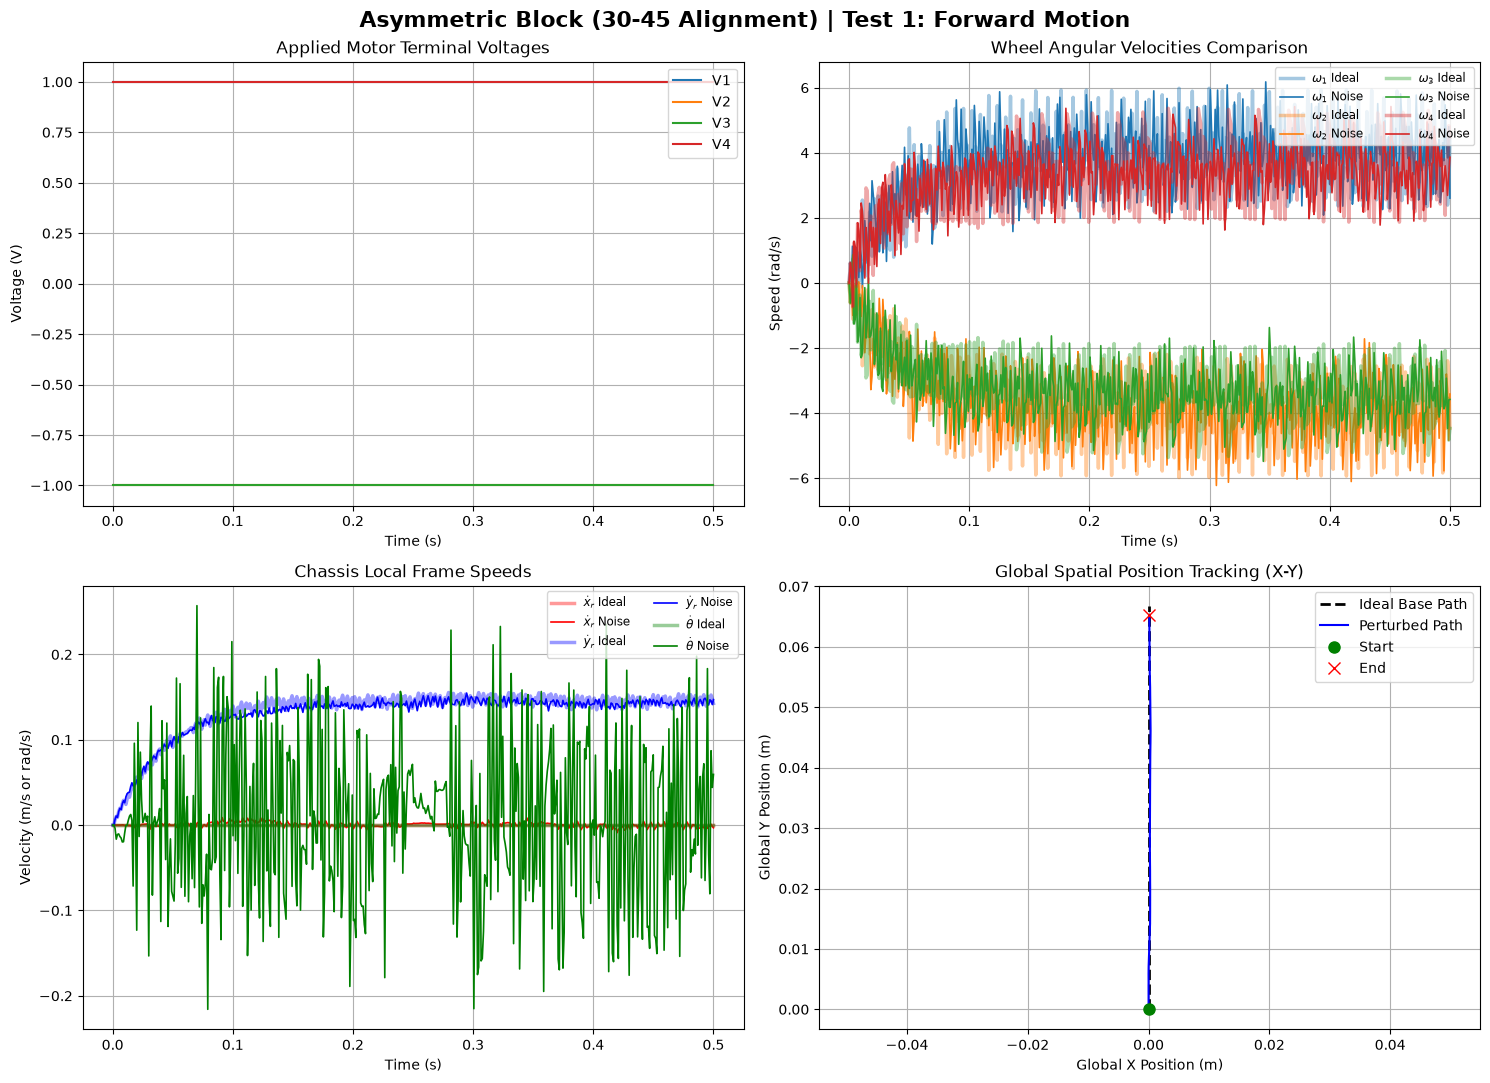

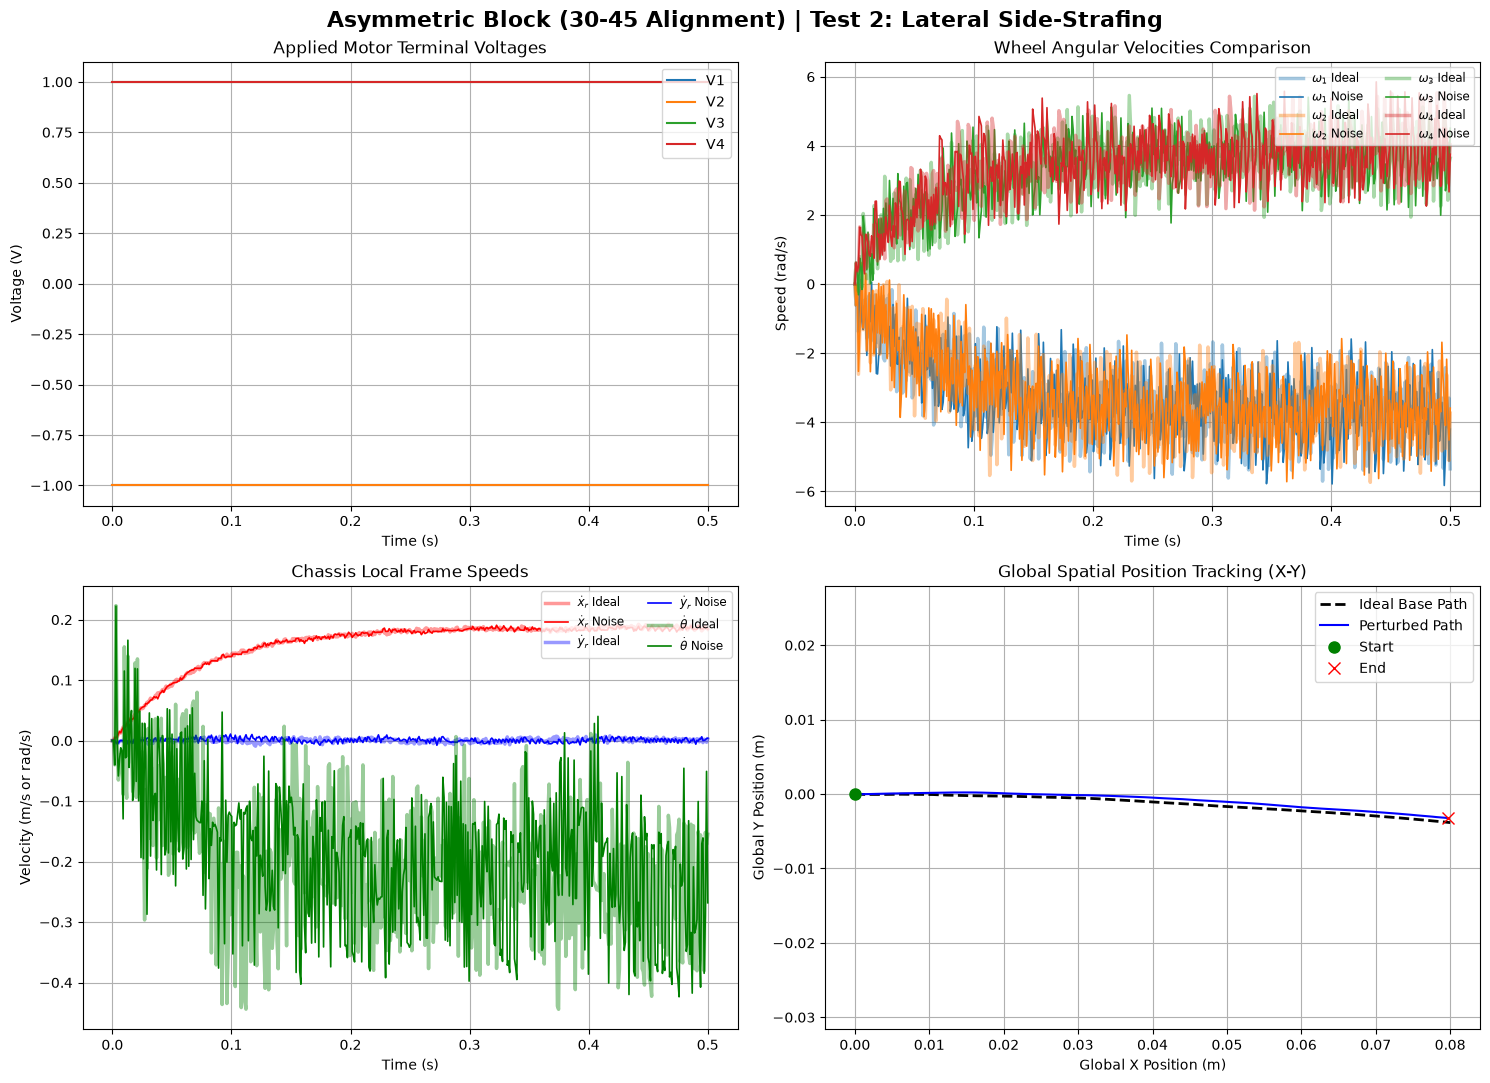

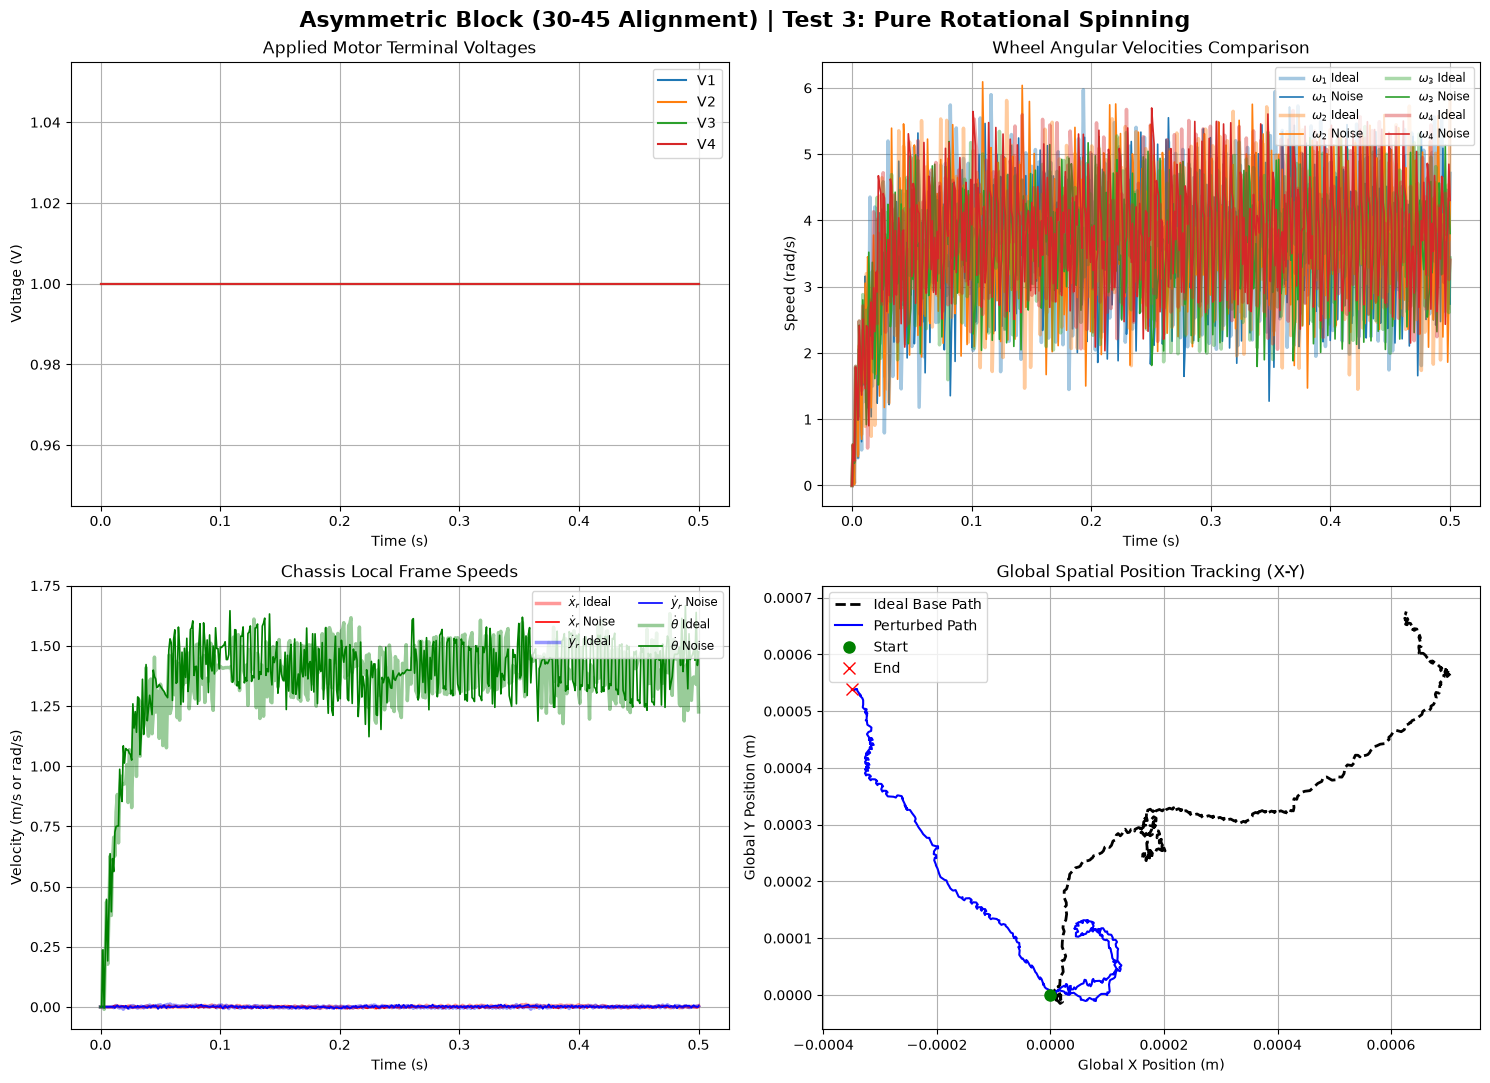

In [87]:
# CONFIGURATION CHANGE: REVERT TO ASYMMETRIC 30-45 DESIGN
simulation_parameters['alpha_f'] = np.radians(30.0)
simulation_parameters['alpha_b'] = np.radians(45.0)

print("Executing Block 2: Asymmetric 30-45 Wheel Angle Configurations...")

for m in maneuvers:
    runs_data = {}
    for condition in ["Ideal", "With Disturbances"]:
        if condition == "Ideal":
            simulation_parameters['sigma_V'] = 0.0
            simulation_parameters['sigma_mu'] = 0.0
        else:
            simulation_parameters['sigma_V'] = nominal_sigma_V
            simulation_parameters['sigma_mu'] = nominal_sigma_mu
            
        robot_plant = OmniRobotSimulation(simulation_parameters, random_seed=42)
        state = OmniMotorState()
        
        v_in_hist, omega_hist, v_local_hist, pos_global_hist = [], [], [], []
        
        for k in range(steps):
            v_in_hist.append(m["V"].copy())
            omega_hist.append(state.omega.copy())
            v_local_hist.append(state.v_local.copy())
            pos_global_hist.append(state.pos_global.copy())
            state, T_load, S_status = robot_plant.step(state, m["V"])
            
        runs_data[condition] = {
            "V": np.array(v_in_hist), "omega": np.array(omega_hist),
            "v_local": np.array(v_local_hist), "pos_global": np.array(pos_global_hist)
        }
        
    ideal = runs_data["Ideal"]
    noisy = runs_data["With Disturbances"]

    fig, axs = plt.subplots(2, 2, figsize=(15, 11))
    fig.suptitle(f"Asymmetric Block (30-45 Alignment) | {m['name']}", fontsize=16, fontweight='bold')
    
    # Subplot 1: Voltage Inputs
    for w in range(4): 
        axs[0, 0].plot(t_vec, ideal["V"][:, w], label=f'V{w+1}')
    axs[0, 0].set_title("Applied Motor Terminal Voltages"); axs[0, 0].set_xlabel("Time (s)"); axs[0, 0].set_ylabel("Voltage (V)"); axs[0, 0].grid(True); axs[0, 0].legend(loc="upper right")
    
    # Subplot 2: Wheel Speeds (FIXED: Raw string notation used)
    for w in range(4):
        axs[0, 1].plot(t_vec, ideal["omega"][:, w], '-', color=f'C{w}', label=r'$\omega_{' + str(w+1) + r'}$ Ideal', **style_ideal)
        axs[0, 1].plot(t_vec, noisy["omega"][:, w], '-', color=f'C{w}', label=r'$\omega_{' + str(w+1) + r'}$ Noise', **style_noisy)
    axs[0, 1].set_title("Wheel Angular Velocities Comparison"); axs[0, 1].set_xlabel("Time (s)"); axs[0, 1].set_ylabel("Speed (rad/s)"); axs[0, 1].grid(True); axs[0, 1].legend(loc="upper right", ncol=2, fontsize='small')
    
    # Subplot 3: Local Frame Chassis Velocities (FIXED: Line parameters isolated)
    axs[1, 0].plot(t_vec, ideal["v_local"][:, 0], 'r-', label=r'$\dot{x}_r$ Ideal', **style_ideal)
    axs[1, 0].plot(t_vec, noisy["v_local"][:, 0], 'r-', label=r'$\dot{x}_r$ Noise', **style_noisy)
    axs[1, 0].plot(t_vec, ideal["v_local"][:, 1], 'b-', label=r'$\dot{y}_r$ Ideal', **style_ideal)
    axs[1, 0].plot(t_vec, noisy["v_local"][:, 1], 'b-', label=r'$\dot{y}_r$ Noise', **style_noisy)
    axs[1, 0].plot(t_vec, ideal["v_local"][:, 2], 'g-', label=r'$\dot{\theta}$ Ideal', **style_ideal)
    axs[1, 0].plot(t_vec, noisy["v_local"][:, 2], 'g-', label=r'$\dot{\theta}$ Noise', **style_noisy)
    axs[1, 0].set_title("Chassis Local Frame Speeds"); axs[1, 0].set_xlabel("Time (s)"); axs[1, 0].set_ylabel("Velocity (m/s or rad/s)"); axs[1, 0].grid(True); axs[1, 0].legend(loc="upper right", ncol=2, fontsize='small')
    
    # Subplot 4: Global Trajectory Plane
    axs[1, 1].plot(ideal["pos_global"][:, 0], ideal["pos_global"][:, 1], 'k--', lw=2.0, label='Ideal Base Path')
    axs[1, 1].plot(noisy["pos_global"][:, 0], noisy["pos_global"][:, 1], 'b-', lw=1.5, label='Perturbed Path')
    axs[1, 1].plot(noisy["pos_global"][0, 0], noisy["pos_global"][0, 1], 'go', markersize=8, label='Start')
    axs[1, 1].plot(noisy["pos_global"][-1, 0], noisy["pos_global"][-1, 1], 'rx', markersize=8, label='End')
    axs[1, 1].set_title("Global Spatial Position Tracking (X-Y)"); axs[1, 1].set_xlabel("Global X Position (m)"); axs[1, 1].set_ylabel("Global Y Position (m)"); axs[1, 1].set_aspect('equal', 'datalim'); axs[1, 1].grid(True); axs[1, 1].legend(loc="best")
    
    plt.tight_layout()
    plt.show()

# Safely restore baseline parameter noise variables back to configuration dictionary
simulation_parameters['sigma_V'] = nominal_sigma_V
simulation_parameters['sigma_mu'] = nominal_sigma_mu


Executing Block 3: Asymmetric 30-45 Wheel Angle Configurations at High Voltage (5.0V)...


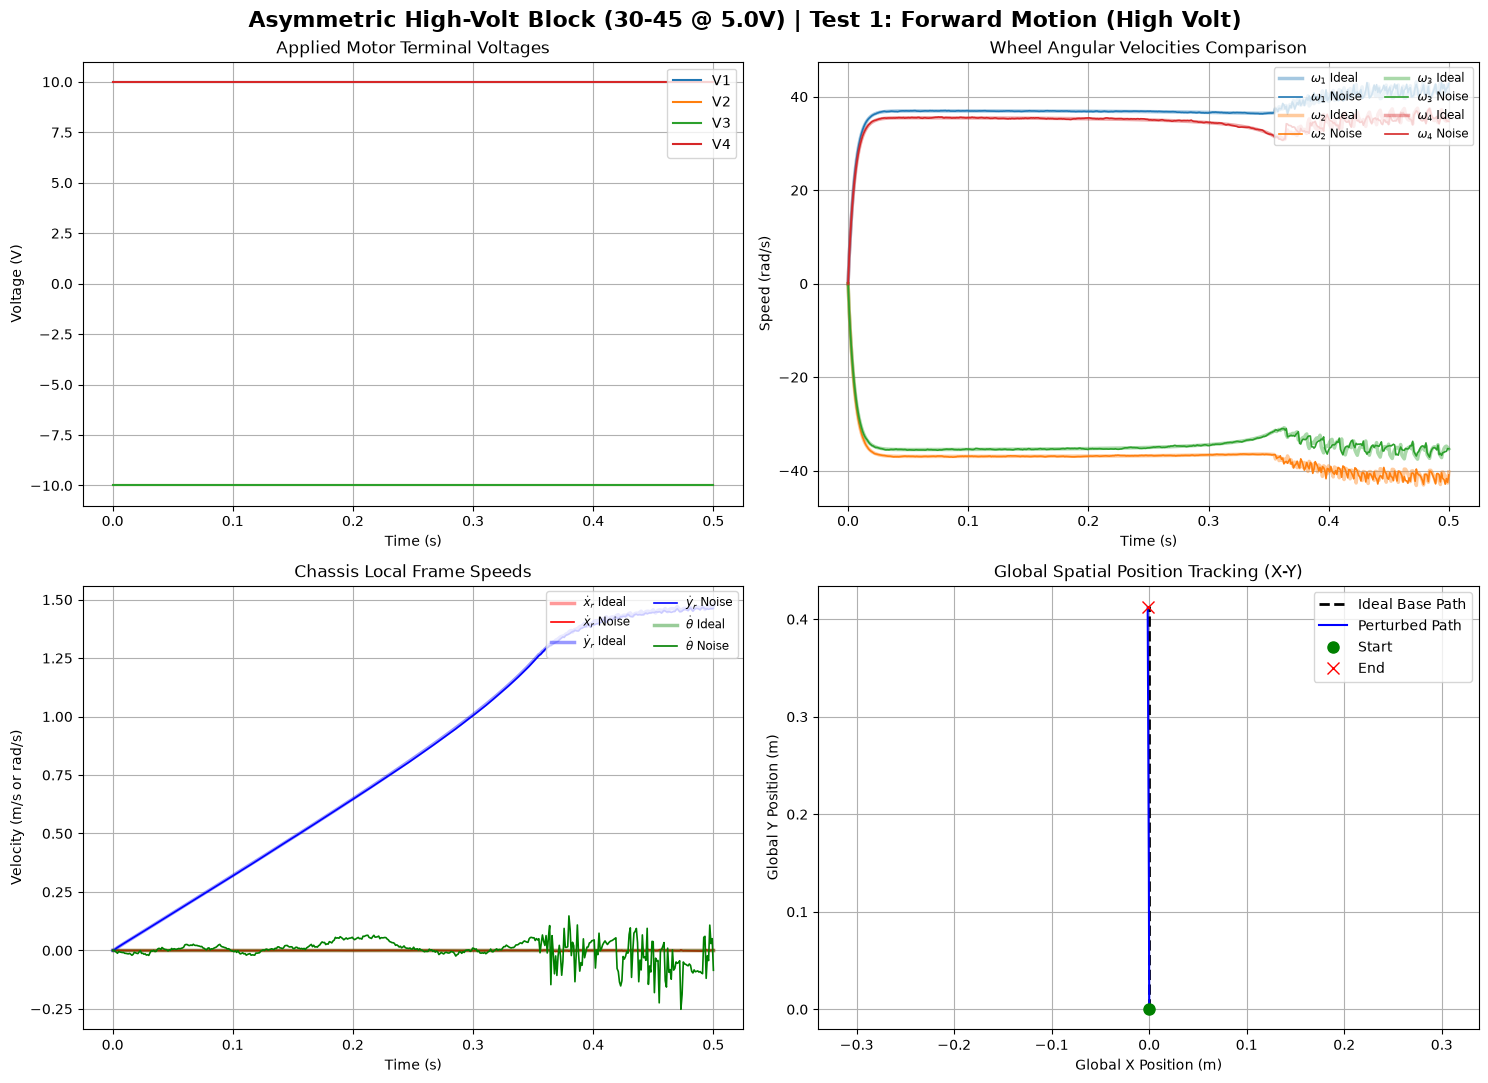

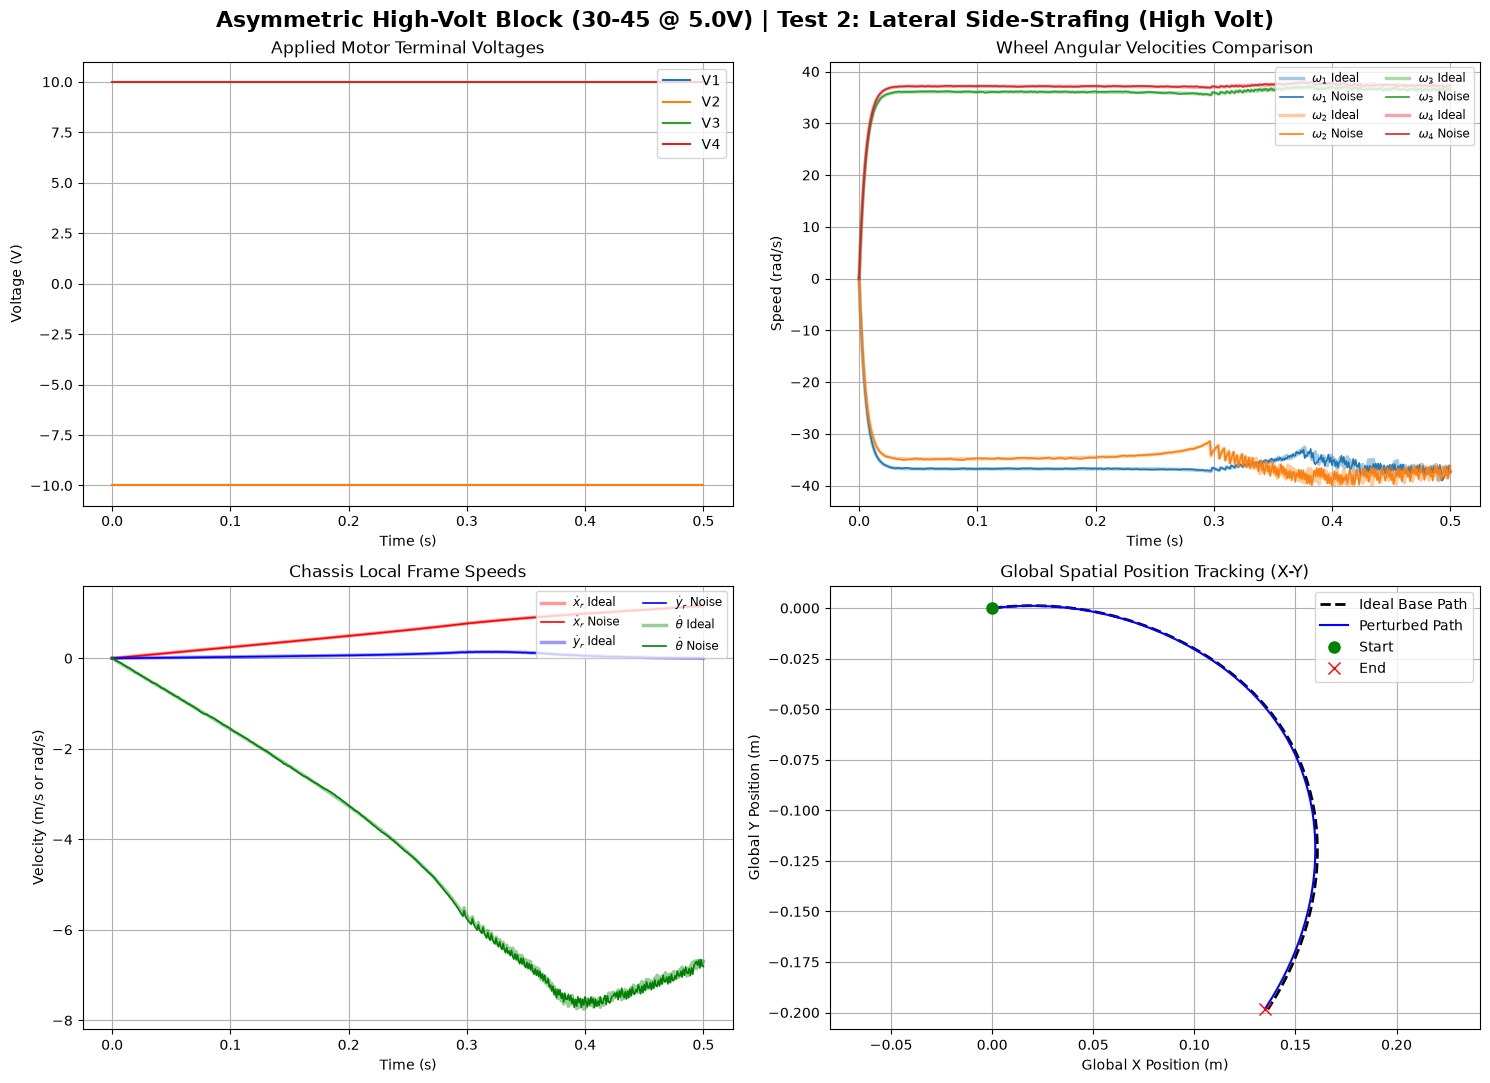

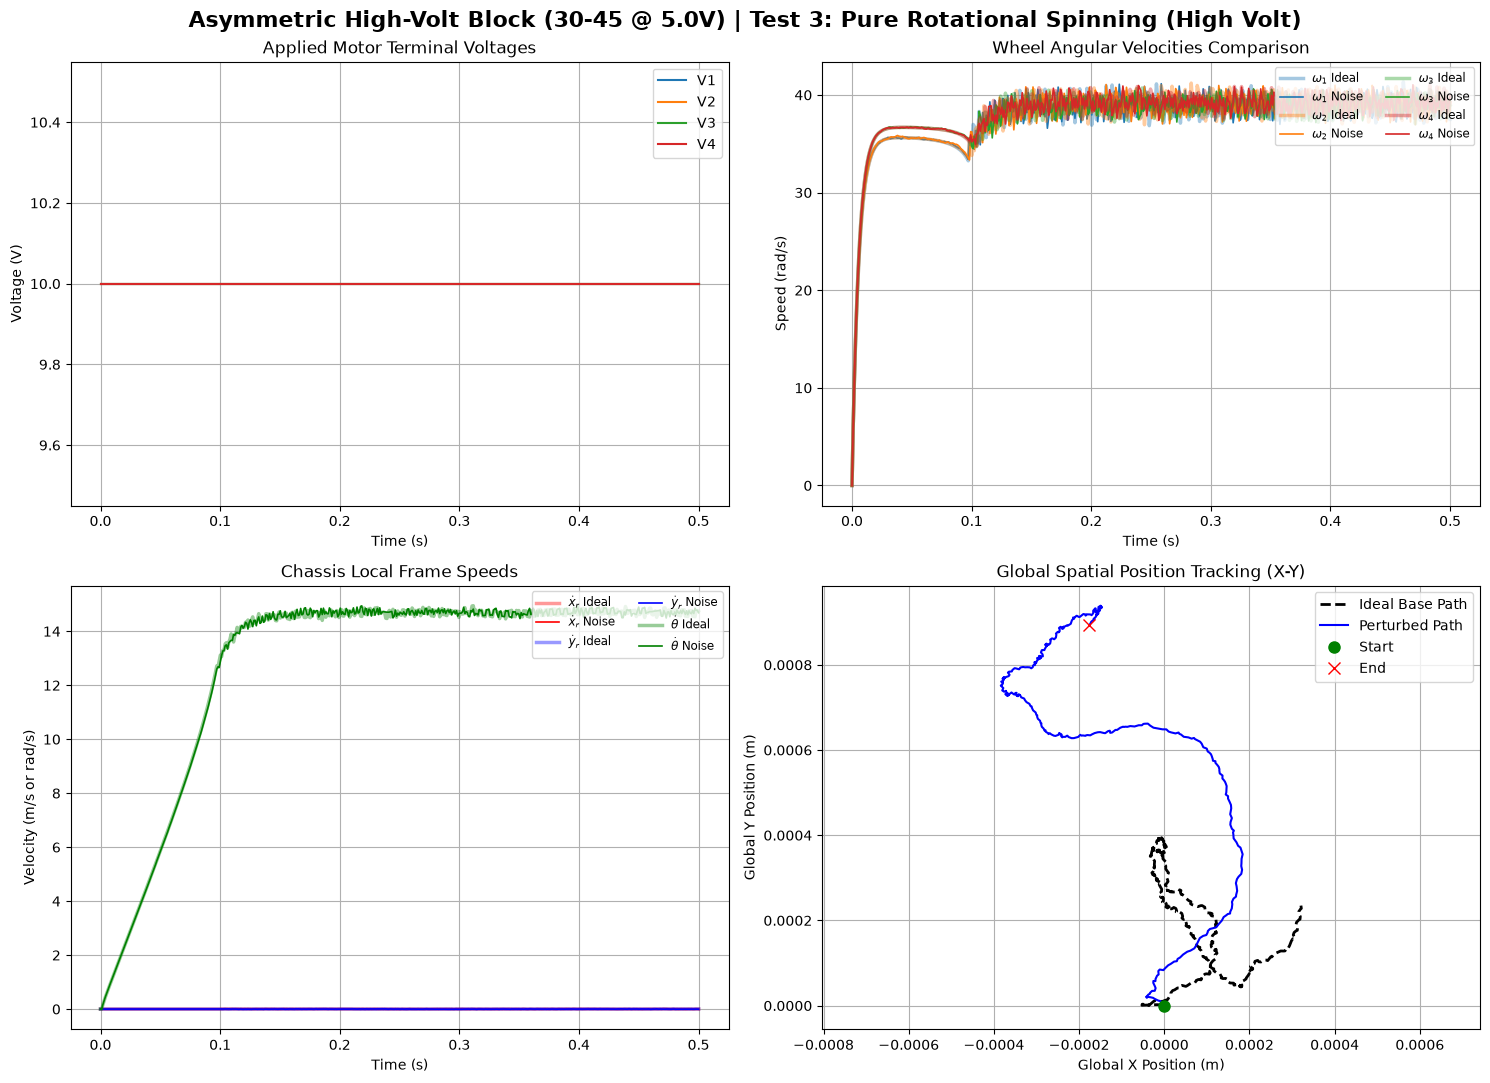

In [ ]:
# =======================================================================
# CONFIGURATION CHANGE: KEEP ASYMMETRIC 30-45 DESIGN BUT BOOSTED VOLTAGE
# =======================================================================
simulation_parameters['alpha_f'] = np.radians(30.0)
simulation_parameters['alpha_b'] = np.radians(45.0)

bost_voltage = 10.0

# Define high-voltage directional maneuvers matching your verified sign choices
high_volt_maneuvers = [
    {"name": "Test 1: Forward Motion (High Volt)", "V": np.array([bost_voltage, -bost_voltage, -bost_voltage, bost_voltage])},
    {"name": "Test 2: Lateral Side-Strafing (High Volt)", "V": np.array([-bost_voltage, -bost_voltage, bost_voltage, bost_voltage])},
    {"name": "Test 3: Pure Rotational Spinning (High Volt)", "V": np.array([bost_voltage, bost_voltage, bost_voltage, bost_voltage])}
]

print("Executing Block 3: Asymmetric 30-45 Wheel Angle Configurations at High Voltage (5.0V)...")

for m in high_volt_maneuvers:
    runs_data = {}
    for condition in ["Ideal", "With Disturbances"]:
        if condition == "Ideal":
            simulation_parameters['sigma_V'] = 0.0
            simulation_parameters['sigma_mu'] = 0.0
        else:
            simulation_parameters['sigma_V'] = nominal_sigma_V
            simulation_parameters['sigma_mu'] = nominal_sigma_mu
            
        # Instantiate plant under custom asymmetric high-volt conditions (Seeded for reproducibility)
        robot_plant = OmniRobotSimulation(simulation_parameters, random_seed=42)
        state = OmniMotorState()
        
        v_in_hist, omega_hist, v_local_hist, pos_global_hist = [], [], [], []
        
        for k in range(steps):
            v_in_hist.append(m["V"].copy())
            omega_hist.append(state.omega.copy())
            v_local_hist.append(state.v_local.copy())
            pos_global_hist.append(state.pos_global.copy())
            state, T_load, S_status = robot_plant.step(state, m["V"])
            
        runs_data[condition] = {
            "V": np.array(v_in_hist), "omega": np.array(omega_hist),
            "v_local": np.array(v_local_hist), "pos_global": np.array(pos_global_hist)
        }
        
    ideal = runs_data["Ideal"]
    noisy = runs_data["With Disturbances"]

    fig, axs = plt.subplots(2, 2, figsize=(15, 11))
    fig.suptitle(f"Asymmetric High-Volt Block (30-45 @ 5.0V) | {m['name']}", fontsize=16, fontweight='bold')
    
    # Subplot 1: Voltage Inputs
    for w in range(4): 
        axs[0, 0].plot(t_vec, ideal["V"][:, w], label=f'V{w+1}')
    axs[0, 0].set_title("Applied Motor Terminal Voltages"); axs[0, 0].set_xlabel("Time (s)"); axs[0, 0].set_ylabel("Voltage (V)"); axs[0, 0].grid(True); axs[0, 0].legend(loc="upper right")
    
    # Subplot 2: Wheel Speeds
    for w in range(4):
        axs[0, 1].plot(t_vec, ideal["omega"][:, w], '-', color=f'C{w}', label=r'$\omega_{' + str(w+1) + r'}$ Ideal', **style_ideal)
        axs[0, 1].plot(t_vec, noisy["omega"][:, w], '-', color=f'C{w}', label=r'$\omega_{' + str(w+1) + r'}$ Noise', **style_noisy)
    axs[0, 1].set_title("Wheel Angular Velocities Comparison"); axs[0, 1].set_xlabel("Time (s)"); axs[0, 1].set_ylabel("Speed (rad/s)"); axs[0, 1].grid(True); axs[0, 1].legend(loc="upper right", ncol=2, fontsize='small')
    
    # Subplot 3: Local Frame Chassis Velocities
    axs[1, 0].plot(t_vec, ideal["v_local"][:, 0], 'r-', label=r'$\dot{x}_r$ Ideal', **style_ideal)
    axs[1, 0].plot(t_vec, noisy["v_local"][:, 0], 'r-', label=r'$\dot{x}_r$ Noise', **style_noisy)
    axs[1, 0].plot(t_vec, ideal["v_local"][:, 1], 'b-', label=r'$\dot{y}_r$ Ideal', **style_ideal)
    axs[1, 0].plot(t_vec, noisy["v_local"][:, 1], 'b-', label=r'$\dot{y}_r$ Noise', **style_noisy)
    axs[1, 0].plot(t_vec, ideal["v_local"][:, 2], 'g-', label=r'$\dot{\theta}$ Ideal', **style_ideal)
    axs[1, 0].plot(t_vec, noisy["v_local"][:, 2], 'g-', label=r'$\dot{\theta}$ Noise', **style_noisy)
    axs[1, 0].set_title("Chassis Local Frame Speeds"); axs[1, 0].set_xlabel("Time (s)"); axs[1, 0].set_ylabel("Velocity (m/s or rad/s)"); axs[1, 0].grid(True); axs[1, 0].legend(loc="upper right", ncol=2, fontsize='small')
    
    # Subplot 4: Global Trajectory Plane
    axs[1, 1].plot(ideal["pos_global"][:, 0], ideal["pos_global"][:, 1], 'k--', lw=2.0, label='Ideal Base Path')
    axs[1, 1].plot(noisy["pos_global"][:, 0], noisy["pos_global"][:, 1], 'b-', lw=1.5, label='Perturbed Path')
    axs[1, 1].plot(noisy["pos_global"][0, 0], noisy["pos_global"][0, 1], 'go', markersize=8, label='Start')
    axs[1, 1].plot(noisy["pos_global"][-1, 0], noisy["pos_global"][-1, 1], 'rx', markersize=8, label='End')
    axs[1, 1].set_title("Global Spatial Position Tracking (X-Y)"); axs[1, 1].set_xlabel("Global X Position (m)"); axs[1, 1].set_ylabel("Global Y Position (m)"); axs[1, 1].set_aspect('equal', 'datalim'); axs[1, 1].grid(True); axs[1, 1].legend(loc="best")
    
    plt.tight_layout()
    plt.show()

# Final safe restoration of baseline parameter noise variables back to dictionary
simulation_parameters['sigma_V'] = nominal_sigma_V
simulation_parameters['sigma_mu'] = nominal_sigma_mu


# 🧪 Multi-Stage Sequence Verification Testing

This section executes verification routines using a **Multi-Stage Step Profile Timeline**. Each directional maneuver commands a voltage profile divided into three 1.0-second stages (Positive Drive $\to$ Negative Plug-Braking $\to$ Zero Coasting). This explicitly evaluates the plant's transient response, deceleration dynamics, and LuGre continuous friction behavior without artificial velocity snapping or numerical chatter.


Executing Profile Tests under Asymmetric 30-45 Geometry...


C:\Users\Dana\AppData\Local\Temp\ipykernel_6184\2344114742.py:106: UserWarning: linestyle is redundantly defined by the 'linestyle' keyword argument and the fmt string "r-" (-> linestyle='-'). The keyword argument will take precedence.
  axs[1, 0].plot(t_vec, ideal["v_local"][:, 0], 'r-', label=r'$\dot{x}_r$ Ideal', **style_ideal)
C:\Users\Dana\AppData\Local\Temp\ipykernel_6184\2344114742.py:107: UserWarning: linestyle is redundantly defined by the 'linestyle' keyword argument and the fmt string "r-" (-> linestyle='-'). The keyword argument will take precedence.
  axs[1, 0].plot(t_vec, noisy["v_local"][:, 0], 'r-', label=r'$\dot{x}_r$ Noise', **style_noisy)
C:\Users\Dana\AppData\Local\Temp\ipykernel_6184\2344114742.py:108: UserWarning: linestyle is redundantly defined by the 'linestyle' keyword argument and the fmt string "b-" (-> linestyle='-'). The keyword argument will take precedence.
  axs[1, 0].plot(t_vec, ideal["v_local"][:, 1], 'b-', label=r'$\dot{y}_r$ Ideal', **style_ideal)
C

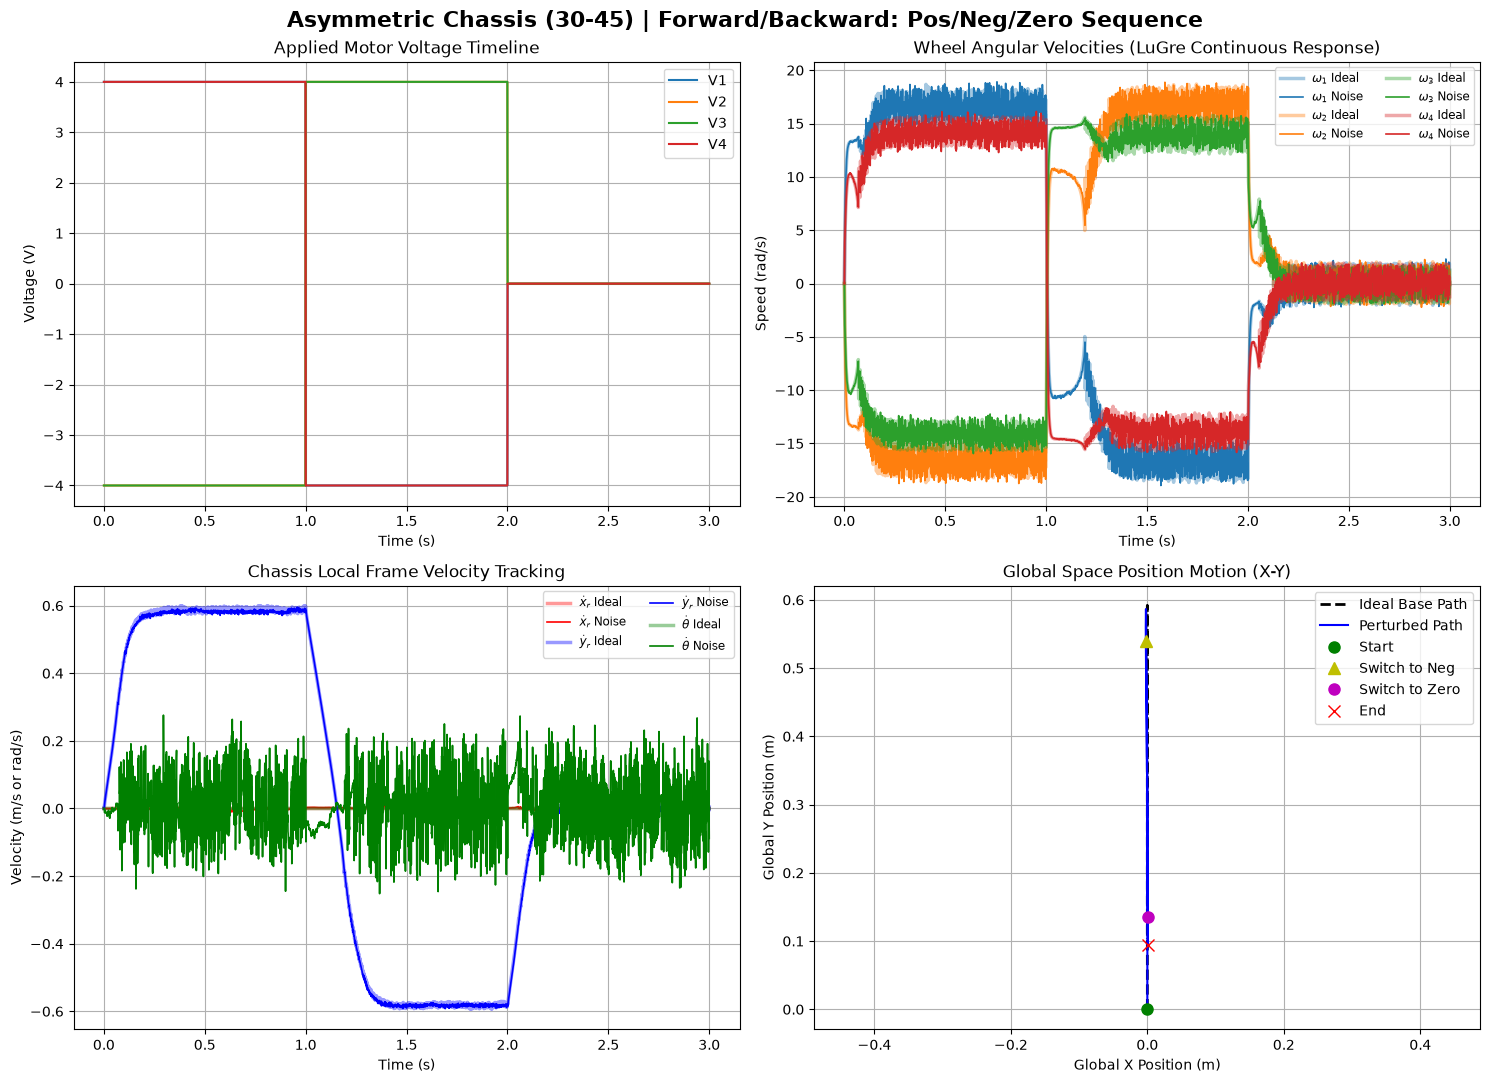

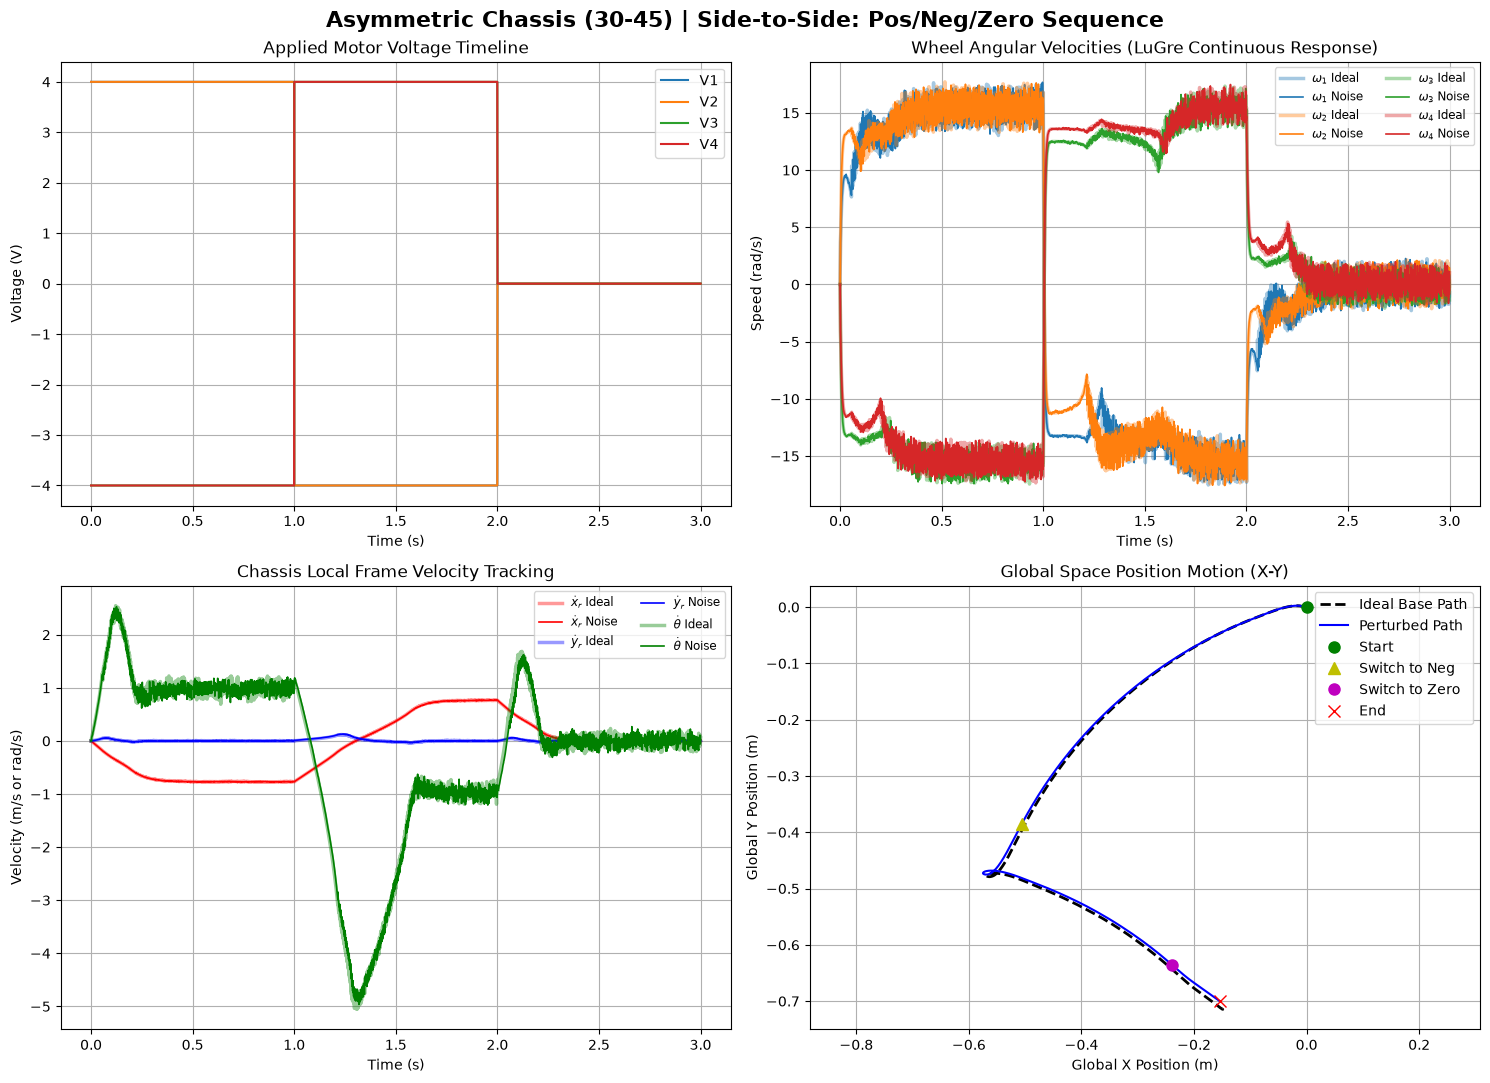

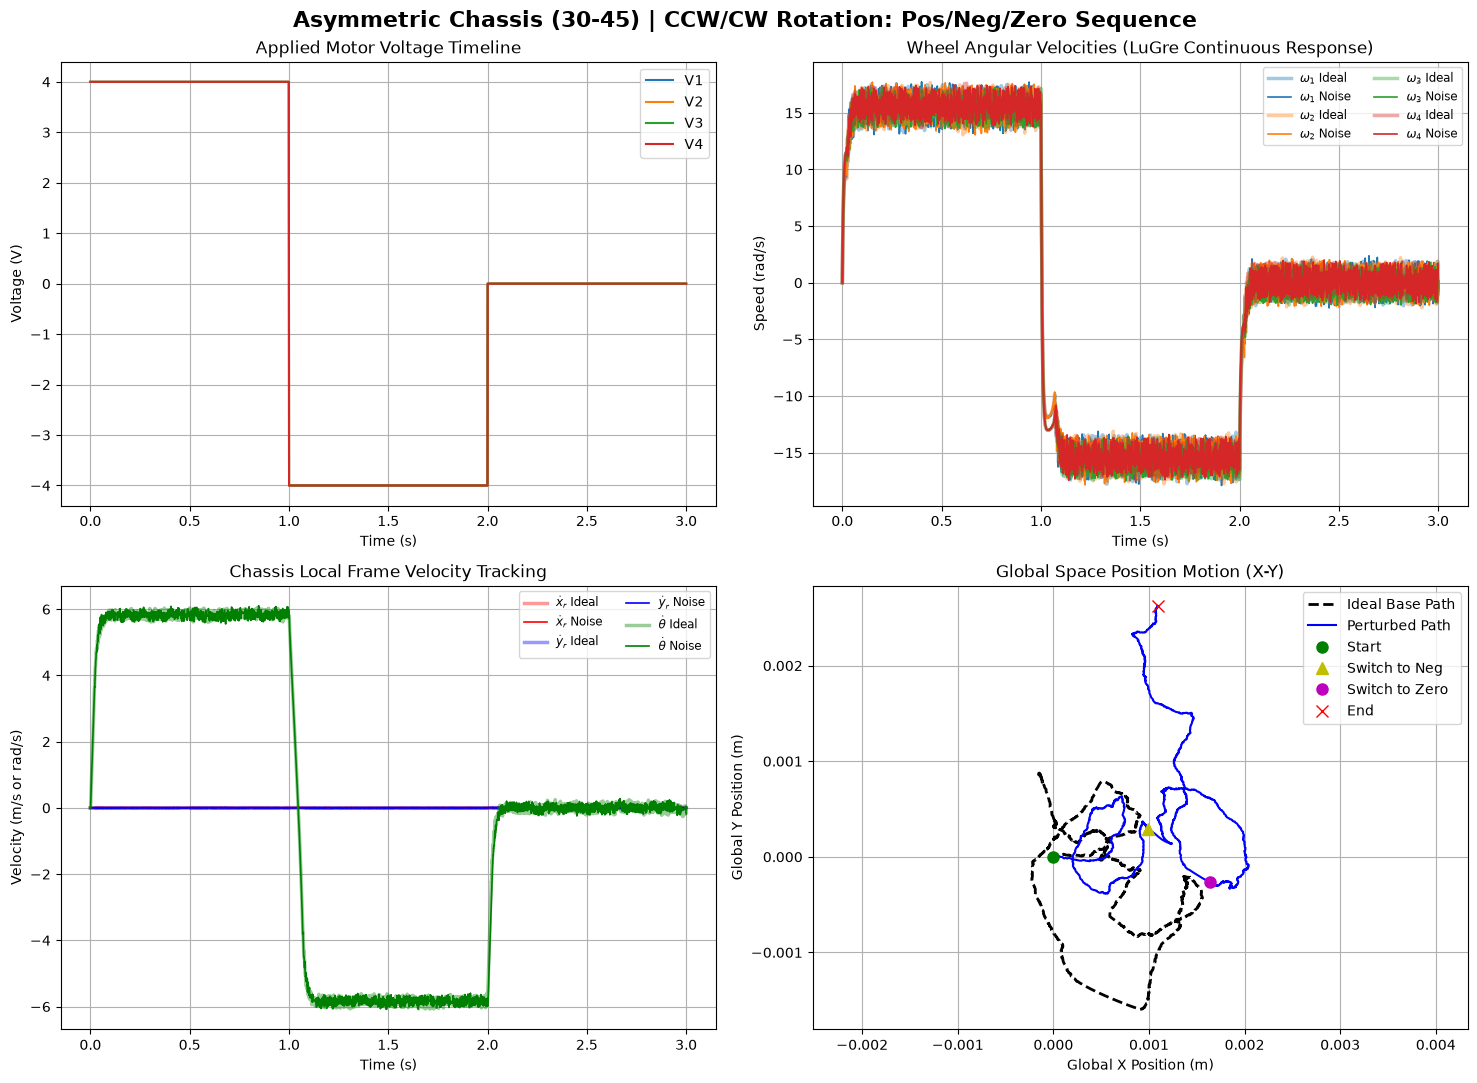

In [89]:
import numpy as np
import matplotlib.pyplot as plt

# Save your configured noise parameters to toggle the passes cleanly
nominal_sigma_V = simulation_parameters['sigma_V']
nominal_sigma_mu = simulation_parameters['sigma_mu']

# Define a 3.0 second timeline split into three distinct 1.0s intervals
t_stage = 1.0
dt = simulation_parameters['dt']
steps_per_stage = int(t_stage / dt)
total_steps = steps_per_stage * 3
t_vec = np.linspace(0, t_stage * 3, total_steps)

# Helper function to dynamically generate the voltage vector at any given step index k
def get_profile_voltage(test_type, step_idx, steps_per_stage):
    # Determine which chronological stage we are currently executing
    if step_idx < steps_per_stage:
        stage = "Positive"
        mag = 4.0
    elif step_idx < 2 * steps_per_stage:
        stage = "Negative"
        mag = -4.0
    else:
        stage = "Zero"
        mag = 0.0
        
    # Apply your verified hardware directional sign combinations scaled by stage magnitude
    if test_type == "Forward/Backward":
        return np.array([mag, -mag, -mag, mag])
    elif test_type == "Side-to-Side":
        return np.array([mag, mag, -mag, -mag])
    elif test_type == "CCW/CW Rotation":
        return np.array([mag, mag, mag, mag])
    return np.zeros(4)

# Define our three complex multi-stage test scenarios
test_scenarios = ["Forward/Backward", "Side-to-Side", "CCW/CW Rotation"]

# Plotting configuration styles
style_ideal = {'ls': '-', 'alpha': 0.4, 'lw': 2.5}  
style_noisy = {'ls': '-', 'alpha': 1.0, 'lw': 1.2}  

# =======================================================================
# STRUCTURAL RUN 1: ASYMMETRIC 30-45 CONFIGURATION WITH PROFILE MANEUVERS
# =======================================================================
simulation_parameters['alpha_f'] = np.radians(30.0)
simulation_parameters['alpha_b'] = np.radians(45.0)

print("Executing Profile Tests under Asymmetric 30-45 Geometry...")

for test_name in test_scenarios:
    runs_data = {}
    
    for condition in ["Ideal", "With Disturbances"]:
        if condition == "Ideal":
            simulation_parameters['sigma_V'] = 0.0
            simulation_parameters['sigma_mu'] = 0.0
        else:
            simulation_parameters['sigma_V'] = nominal_sigma_V
            simulation_parameters['sigma_mu'] = nominal_sigma_mu
            
        robot_plant = OmniRobotSimulation(simulation_parameters, random_seed=42)
        state = OmniMotorState()
        
        v_in_hist, omega_hist, v_local_hist, pos_global_hist = [], [], [], []
        
        # Step through the full 3.0 second timeline
        for k in range(total_steps):
            V_cmd = get_profile_voltage(test_name, k, steps_per_stage)
            
            v_in_hist.append(V_cmd.copy())
            omega_hist.append(state.omega.copy())
            v_local_hist.append(state.v_local.copy())
            pos_global_hist.append(state.pos_global.copy())
            
            state, T_load, S_status = robot_plant.step(state, V_cmd)
            
        runs_data[condition] = {
            "V": np.array(v_in_hist), "omega": np.array(omega_hist),
            "v_local": np.array(v_local_hist), "pos_global": np.array(pos_global_hist)
        }
        
    ideal = runs_data["Ideal"]
    noisy = runs_data["With Disturbances"]

    # -------------------------------------------------------------------
    # GENERATE 2x2 GRAPHS FOR COMPLEX PROFILE COUPLING
    # -------------------------------------------------------------------
    fig, axs = plt.subplots(2, 2, figsize=(15, 11))
    fig.suptitle(f"Asymmetric Chassis (30-45) | {test_name}: Pos/Neg/Zero Sequence", fontsize=16, fontweight='bold')
    
    # Subplot 1: Voltage Profiles (Now showing step changes over time)
    for w in range(4): 
        axs[0, 0].plot(t_vec, ideal["V"][:, w], label=f'V{w+1}')
    axs[0, 0].set_title("Applied Motor Voltage Timeline")
    axs[0, 0].set_xlabel("Time (s)"); axs[0, 0].set_ylabel("Voltage (V)"); axs[0, 0].grid(True); axs[0, 0].legend(loc="upper right")
    
    # Subplot 2: Wheel Speeds showing spikes during aggressive direction switches
    for w in range(4):
        axs[0, 1].plot(t_vec, ideal["omega"][:, w], color=f'C{w}', label=r'$\omega_{' + str(w+1) + r'}$ Ideal', **style_ideal)
        axs[0, 1].plot(t_vec, noisy["omega"][:, w], color=f'C{w}', label=r'$\omega_{' + str(w+1) + r'}$ Noise', **style_noisy)
    axs[0, 1].set_title("Wheel Angular Velocities (LuGre Continuous Response)"); axs[0, 1].set_xlabel("Time (s)"); axs[0, 1].set_ylabel("Speed (rad/s)"); axs[0, 1].grid(True); axs[0, 1].legend(loc="upper right", ncol=2, fontsize='small')
    
    # Subplot 3: Local Frame Velocities showing Braking/Deceleration Curves
    axs[1, 0].plot(t_vec, ideal["v_local"][:, 0], 'r-', label=r'$\dot{x}_r$ Ideal', **style_ideal)
    axs[1, 0].plot(t_vec, noisy["v_local"][:, 0], 'r-', label=r'$\dot{x}_r$ Noise', **style_noisy)
    axs[1, 0].plot(t_vec, ideal["v_local"][:, 1], 'b-', label=r'$\dot{y}_r$ Ideal', **style_ideal)
    axs[1, 0].plot(t_vec, noisy["v_local"][:, 1], 'b-', label=r'$\dot{y}_r$ Noise', **style_noisy)
    axs[1, 0].plot(t_vec, ideal["v_local"][:, 2], 'g-', label=r'$\dot{\theta}$ Ideal', **style_ideal)
    axs[1, 0].plot(t_vec, noisy["v_local"][:, 2], 'g-', label=r'$\dot{\theta}$ Noise', **style_noisy)
    axs[1, 0].set_title("Chassis Local Frame Velocity Tracking"); axs[1, 0].set_xlabel("Time (s)"); axs[1, 0].set_ylabel("Velocity (m/s or rad/s)"); axs[1, 0].grid(True); axs[1, 0].legend(loc="upper right", ncol=2, fontsize='small')
    
    # Subplot 4: Global Trajectory Plane showing bidirectional path trace
    axs[1, 1].plot(ideal["pos_global"][:, 0], ideal["pos_global"][:, 1], 'k--', lw=2.0, label='Ideal Base Path')
    axs[1, 1].plot(noisy["pos_global"][:, 0], noisy["pos_global"][:, 1], 'b-', lw=1.5, label='Perturbed Path')
    axs[1, 1].plot(noisy["pos_global"][0, 0], noisy["pos_global"][0, 1], 'go', markersize=8, label='Start')
    axs[1, 1].plot(noisy["pos_global"][steps_per_stage, 0], noisy["pos_global"][steps_per_stage, 1], 'y^', markersize=8, label='Switch to Neg')
    axs[1, 1].plot(noisy["pos_global"][2*steps_per_stage, 0], noisy["pos_global"][2*steps_per_stage, 1], 'mo', markersize=8, label='Switch to Zero')
    axs[1, 1].plot(noisy["pos_global"][-1, 0], noisy["pos_global"][-1, 1], 'rx', markersize=8, label='End')
    axs[1, 1].set_title("Global Space Position Motion (X-Y)"); axs[1, 1].set_xlabel("Global X Position (m)"); axs[1, 1].set_ylabel("Global Y Position (m)"); axs[1, 1].set_aspect('equal', 'datalim'); axs[1, 1].grid(True); axs[1, 1].legend(loc="best")
    
    plt.tight_layout()
    plt.show()

# Restore baseline parameters securely
simulation_parameters['sigma_V'] = nominal_sigma_V
simulation_parameters['sigma_mu'] = nominal_sigma_mu
